## Analysis contexts

**Common cohort (N=110) provides the matched basis for cross-modality predictive comparison.** Full availability (N=149) preserves the modality-specific results. The two contexts are compared section by section. Model families are selected by mean inner-CV macro-F1, not outer-test performance. Differences cannot be attributed solely to sample size because preprocessing and search spaces also differ.

Training is disabled by default; reporting cells load the saved common-cohort results.

In [1]:
# Display precision only; analytical values and saved artifacts stay unchanged.
from pathlib import Path as _DisplayPath
import sys as _display_sys
_display_root = _DisplayPath.cwd()
while not (_display_root / "scripts").is_dir() and _display_root != _display_root.parent:
    _display_root = _display_root.parent
if str(_display_root) not in _display_sys.path:
    _display_sys.path.insert(0, str(_display_root))
from scripts.OligoPolyThesis.utils_ml_oligopoly import thesis_display, thesis_print

from pathlib import Path as P110Path
import sys as p110_sys
import pandas as p110_pd
from IPython.display import display, Image as P110Image, Markdown as P110Markdown
p110_repo = next(p for p in [P110Path.cwd(), *P110Path.cwd().parents] if (p / 'scripts/OligoPolyThesis').is_dir())
if str(p110_repo) not in p110_sys.path:
    p110_sys.path.insert(0, str(p110_repo))
from scripts.OligoPolyThesis.utils_ml_oligopoly import load_primary110, _primary110_reporting_CONFIG as P110_CONFIG
p110_root = P110Path('/mnt/data3/MCPP-Breast/Machine-Learning-Models-poly_vs_oligo/Common-Cohort-Modality-Comparison')
p110_bundle = load_primary110(p110_root)

p110_config = 'clinical'
p110_output = p110_root / 'primary_110' / p110_config
p110_context = p110_pd.read_csv(p110_output / f'{p110_config}_primary_110_context_comparison.csv')
p110_context['analysis_context'] = ['Full availability (N=149)', 'Common cohort (N=110)']
p110_secondary_label, p110_primary_label = 'Full availability (N=149)', 'Common cohort (N=110)'
p110_folder, p110_prefix, p110_secondary_family, *_ = P110_CONFIG[p110_config]
p110_primary_family = p110_context.iloc[1].selected_family


# Clinical Data Modelling with Nested Cross-Validation

This notebook evaluates whether the preprocessed clinical variables distinguish oligometastatic from polymetastatic breast cancer.

The dataset used here contains baseline clinical variables selected during preprocessing to support prediction from information available before or at the primary tumour setting. Variables that could introduce information leakage, have insufficient data quality, or are not suitable for the intended prediction task were removed during preprocessing.

## Input

* `20260401-mcpp-breast-clinical-all-metastatic-data-preprocessing-without-treatment.csv`: final clinical dataset after preprocessing, feature engineering, filtering, encoding, grouping of selected categorical variables, removal of highly correlated features, and removal of treatment-related variables.

## Objective

The goal is to evaluate whether baseline clinical variables can distinguish between:

* `0` = oligometastatic;
* `1` = polymetastatic.

The final target variable is named `Polymetastatic`.

## Models

The following candidate model families are evaluated:

* Logistic Regression with L2 regularization (`logreg_l2`);
* Logistic Regression with L1 regularization (`logreg_l1`);
* Random Forest (`random_forest`);
* XGBoost classifier (`xgboost`).

For logistic regression and random forest, class weighting is included in the hyperparameter grid. This allows the inner cross-validation loop to compare default class weights against `class_weight="balanced"`.

For XGBoost, class imbalance is handled through `scale_pos_weight`. In this original full-availability workflow, the class ratio is calculated once from the complete modelling cohort and then included in the XGBoost hyperparameter grid. This differs from the later common-cohort (N=110) analysis, where class weighting is determined within the training data.

## Validation Strategy

Nested cross-validation is used to obtain a more reliable estimate of model performance while tuning hyperparameters.

* Outer cross-validation is used for model evaluation.
* Inner cross-validation is used for hyperparameter tuning.

Hyperparameter selection is performed using macro-F1 within the inner cross-validation loop.
Macro-F1 was used as the model-selection metric for consistency across the clinical, mutation, and combined modelling workflows.

For each candidate model family, hyperparameters are selected using only the training data from each outer fold. The selected model family is then chosen according to the mean inner-cross-validation score across outer folds.

The outer-fold test metrics are used only to estimate out-of-training performance for each modelling strategy. 

This strategy is appropriate for small-sample biomedical datasets, where standard cross-validation can lead to overly optimistic performance estimates.

## Outputs

This notebook generates and saves tabular results, and displays diagnostic plots:

* fold-level test results;
* fold-level train results;
* fold-level predictions;
* train-versus-test performance comparison;
* model selection summary based on mean inner-cross-validation score;
* ROC curves and confusion matrices displayed in the notebook;
* fold-level feature rankings for each model.




In [1]:
import os
import sys
import pandas as pd
import json

from pathlib import Path
from sklearn.model_selection import StratifiedKFold
from flaml import AutoML
import matplotlib.pyplot as plt


## Import Utility Functions

All required modelling and plotting functions are imported from the thesis-specific module `scripts.OligoPolyThesis.utils_ml_oligopoly`.

In [2]:
# ── Project root setup ───────────────────────────────────────────────────
ROOT = Path.cwd()
while not (ROOT / "scripts").exists() and ROOT != ROOT.parent:
    ROOT = ROOT.parent

if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

from scripts.OligoPolyThesis.utils_ml_oligopoly import (
    build_models_clinical,
    run_nested_cv_with_predictions_clinical,
    plot_best_inner_score_histogram_and_folds,
    plot_calibration_curve,
    run_nested_cv_with_flaml_clinical,
    plot_roc_curves,
    plot_confusion_matrix,
    plot_combined_ranking,
    plot_precision_recall_curves,
    clinical_binary_metrics, 
    clinical_outer_splits, 
    validate_clinical_oof,
    rank_clinical_inner_scores, 
    clinical_flaml_settings,
)
from scripts.OligoPolyThesis.utils_ml_oligopoly import (
    plot_clinical_apparent_heldout,
    plot_thesis_saved_figure,
)

## Clinical dataset

The input is the final dataset from the clinical preprocessing notebook.

In [ ]:
# Input data path

data_path_directory = "/mnt/data3/MCPP-Breast/Clinical-Data/"
file_path = os.path.join(
    data_path_directory,
    "20260401-mcpp-breast-clinical-all-metastatic-data-preprocessing-without-treatment.csv"
)

# Output path for results

output_dir = "/mnt/data3/MCPP-Breast/Machine-Learning-Models-poly_vs_oligo/Clinical-Data"
os.makedirs(output_dir, exist_ok=True)


df_clinical = pd.read_csv(file_path, sep=';')

thesis_print("Clinical dataset shape:", df_clinical.shape)

## Define Target and Predictor Matrix

The final target variable used in this notebook is `Polymetastatic`:

- `0` = oligometastatic;
- `1` = polymetastatic.

The predictor matrix contains the clinical variables retained after preprocessing.

The following columns are excluded from the predictor matrix:

- `record_id`, because it is only a patient identifier;
- `sample_id`, because it is only a sample identifier;
- `Polymetastatic`, because it is the target variable.

In [4]:
X = df_clinical.drop(columns=["record_id", "sample_id", "Polymetastatic"])
y = df_clinical["Polymetastatic"].astype(int)

thesis_print("X shape:", X.shape)
thesis_print("y distribution:")
thesis_print(y.value_counts())

X shape: (149, 23)
y distribution:
Polymetastatic
1    85
0    64
Name: count, dtype: int64


## Check Feature Types

Before modelling, we inspect the feature types to confirm that the predictor matrix is numeric and suitable for the candidate machine learning models.

In [5]:
thesis_print("Feature dtypes:")
thesis_display(X.dtypes.value_counts())

thesis_print("First feature types:")
thesis_display(X.dtypes.head(20))

Feature dtypes:


int64      22
float64     1
Name: count, dtype: int64

First feature types:


age_at_diagnosis       float64
abc_breast_side_1.0      int64
abc_grade_3.0            int64
abc_re_1.0               int64
abc_rp_1.0               int64
luminal_b_1.0            int64
abc_p53_1.0              int64
abc_p53_2.0              int64
abc_p53_3.0              int64
abc_ajcc_m_3.0           int64
abc_ajcc_x_t_6.0         int64
abc_ajcc_x_t_7.0         int64
abc_ajcc_x_n_10.0        int64
abc_ajcc_x_n_14.0        int64
abc_ajcc_x_n_15.0        int64
abc_ajcc_x_n_19.0        int64
abc_grade_1-2            int64
abc_her2_positive        int64
abc_ajcc_x_n_N0          int64
abc_ajcc_x_n_N1          int64
dtype: object

### Convert `age_at_diagnosis` to Integer

The variable `age_at_diagnosis` represents age in years. It is converted to integer format for consistency before modelling.

In [6]:
X["age_at_diagnosis"] = X["age_at_diagnosis"].astype(int)

### Cohort comparison

Full availability retains the patients available to the modality. The common-cohort comparison uses identical patient membership and frozen outer-fold assignments across all seven inputs.

In [2]:
thesis_display(p110_pd.DataFrame([
    {'Context': p110_secondary_label, 'N': 149, 'Oligometastatic': 64, 'Polymetastatic': 85},
    {'Context': p110_primary_label, 'N': 110, 'Oligometastatic': 43, 'Polymetastatic': 67},
]))
thesis_display(p110_pd.crosstab(p110_bundle['cohort'].outer_fold, p110_bundle['cohort'].y_true).rename(columns={0:'Oligometastatic',1:'Polymetastatic'}))

,Context,N,Oligometastatic,Polymetastatic
0,Full availability (N=149),149,64,85
1,Common cohort (N=110),110,43,67


y_true,Oligometastatic,Polymetastatic
outer_fold,,
1,8,14
2,8,14
3,9,13
4,9,13
5,9,13


## Define Nested Cross-Validation Strategy

We use:

- 5-fold stratified outer cross-validation for model evaluation;
- 5-fold stratified inner cross-validation for hyperparameter tuning.

Stratification preserves the class distribution across folds.

This setup separates hyperparameter selection from model evaluation, reducing optimistic bias in performance estimates.

In [7]:
RANDOM_STATE = 42

outer_cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
inner_cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

SELECTION_SCORING = "f1_macro"
# Freeze outer indices once; inner_cv splits each outer-training subset locally.
outer_splits = clinical_outer_splits(outer_cv, X, y)
RUN_FLAML = False
RUN_FULL_COHORT_FLAML = False
FLAML_TIME_BUDGET_SECONDS = 120


## Define Candidate Models

The following model families are compared:

- Logistic Regression with L2 regularization;
- Logistic Regression with L1 regularization;
- Random Forest;
- XGBoost.

For logistic regression and Random Forest, class weighting is treated as a hyperparameter in the inner cross-validation loop.

For XGBoost, `scale_pos_weight` is based on the oligometastatic-to-polymetastatic class ratio calculated from the complete N=149 modelling cohort. This is part of the original workflow and is retained here for reproducibility; the later common-cohort (N=110) analysis uses fit-local class weighting.


In [8]:
# Compute class-imbalance ratio for XGBoost

n_negative = (y == 0).sum()
n_positive = (y == 1).sum()

xgb_scale_pos_weight = n_negative / n_positive

thesis_print("Number of oligometastatic patients (class 0):", n_negative)
thesis_print("Number of polymetastatic patients (class 1):", n_positive)
thesis_print("XGBoost scale_pos_weight:", xgb_scale_pos_weight)

models = build_models_clinical(
    random_state=RANDOM_STATE,
    xgb_scale_pos_weight=xgb_scale_pos_weight
)

thesis_print("Candidate models:")
thesis_print(list(models.keys()))

Number of oligometastatic patients (class 0): 64
Number of polymetastatic patients (class 1): 85
XGBoost scale_pos_weight: 0.7529411764705882
Candidate models:
['logreg_l2', 'logreg_l1', 'random_forest', 'xgboost']


## Run Nested Cross-Validation and Save Intermediate Results

We run nested CV and save:
- outer-fold test results;
- outer-fold train results;
- fold-level predictions;
- fold-level feature rankings extracted from the fitted best estimator in each outer fold.

Saving the feature rankings during nested cross-validation avoids refitting models later only to recover coefficients or feature importances.

Hyperparameters are selected in the inner loop using **macro-F1**.

Macro-F1 gives equal weight to both classes and was used consistently across the clinical, mutation, and combined modelling workflows.

In [9]:
RUN_NESTED_CV = False

if RUN_NESTED_CV:
    results_test_df, results_train_df, predictions_df, feature_rankings_df = (
        run_nested_cv_with_predictions_clinical(
            X=X,
            y=y,
            record_ids=df_clinical["record_id"],
            sample_ids=df_clinical["sample_id"],
            models=models,
            outer_cv=outer_splits,
            inner_cv=inner_cv,
            scoring=SELECTION_SCORING,
            n_jobs=-1,
            coefficient_threshold=1e-8,
            top_n_tree=20
        )
    )

    results_test_df.to_csv(
        os.path.join(output_dir, "clinical_nested_cv_test_results.csv"),
        index=False
    )

    results_train_df.to_csv(
        os.path.join(output_dir, "clinical_nested_cv_train_results.csv"),
        index=False
    )

    predictions_df.to_csv(
        os.path.join(output_dir, "clinical_nested_cv_predictions.csv"),
        index=False
    )

    feature_rankings_df.to_csv(
        os.path.join(output_dir, "clinical_nested_cv_feature_rankings.csv"),
        index=False
    )

else:
    results_test_df = pd.read_csv(
        os.path.join(output_dir, "clinical_nested_cv_test_results.csv")
    )

    results_train_df = pd.read_csv(
        os.path.join(output_dir, "clinical_nested_cv_train_results.csv")
    )

    predictions_df = pd.read_csv(
        os.path.join(output_dir, "clinical_nested_cv_predictions.csv")
    )

    feature_rankings_df = pd.read_csv(
        os.path.join(output_dir, "clinical_nested_cv_feature_rankings.csv")
    )


=== Running model: logreg_l2 ===
Outer fold 1/5

--- Calculating Model Performance Metrics ---
Accuracy: 0.600
F1_score: 0.625
Sensitivity: 0.588
Specificity: 0.615
Auc_score: 0.624
Precision: 0.667

Metrics calculated successfully.

--- Calculating Model Performance Metrics ---
Accuracy: 0.672
F1_score: 0.698
Sensitivity: 0.662
Specificity: 0.686
Auc_score: 0.720
Precision: 0.738

Metrics calculated successfully.
Outer fold 2/5

--- Calculating Model Performance Metrics ---
Accuracy: 0.667
F1_score: 0.737
Sensitivity: 0.824
Specificity: 0.462
Auc_score: 0.652
Precision: 0.667

Metrics calculated successfully.

--- Calculating Model Performance Metrics ---
Accuracy: 0.647
F1_score: 0.667
Sensitivity: 0.618
Specificity: 0.686
Auc_score: 0.710
Precision: 0.724

Metrics calculated successfully.
Outer fold 3/5

--- Calculating Model Performance Metrics ---
Accuracy: 0.533
F1_score: 0.611
Sensitivity: 0.647
Specificity: 0.385
Auc_score: 0.511
Precision: 0.579

Metrics calculated successful

In [10]:
# Validate saved held-out predictions before deriving any new reports.
validated_oof_by_model = {
    name: validate_clinical_oof(predictions_df, name, df_clinical, outer_splits)
    for name in models
}
# Retain frozen estimates; add previously unavailable test metrics from saved OOF rows.
# The legacy f1_score column is positive-class F1, not macro-F1.
additional_fold_metrics = []
for name, frame in validated_oof_by_model.items():
    for fold, fold_frame in frame.groupby("outer_fold"):
        metrics = clinical_binary_metrics(fold_frame.y_true, fold_frame.y_pred, fold_frame.y_proba)
        additional_fold_metrics.append({"model": name, "outer_fold": fold,
            **{key: metrics[key] for key in ["macro_f1", "average_precision", "brier_score"]}})
additional_fold_metrics = pd.DataFrame(additional_fold_metrics)
report_test_df = results_test_df.drop(
    columns=["macro_f1", "average_precision", "brier_score"], errors="ignore"
).merge(additional_fold_metrics, on=["model", "outer_fold"], validate="one_to_one")

### Train–test diagnostics by context

The first table compares the selected family in each context. Train and outer-test AUC are means across five outer folds; the gap is their difference. The all-family common-cohort table is a secondary diagnostic, not a selection criterion.

In [3]:
p110_diagnostics = p110_pd.read_csv(p110_output / f'{p110_config}_primary_110_train_test.csv')
p110_primary_diag = p110_diagnostics.set_index('family').loc[p110_primary_family]
if p110_config == 'transcriptomics':
    p110_secondary_diag = p110_pd.read_csv(p110_root.parent / p110_folder / 'transcriptomics_representation_model_selection_summary_reviewed.csv').set_index('representation').loc[p110_secondary_family]
    p110_secondary_train = p110_secondary_diag['mean_train_roc_auc']
    p110_secondary_test = p110_secondary_diag['mean_test_roc_auc']
    p110_secondary_gap = p110_secondary_diag['train_test_gap']
else:
    p110_secondary_diag = p110_pd.read_csv(p110_root.parent / p110_folder / f'{p110_prefix}_train_test_comparison_reviewed.csv').set_index('model').loc[p110_secondary_family]
    p110_auc_key = 'auc_score' if p110_config == 'clinical' else 'roc_auc'
    p110_secondary_train = p110_secondary_diag[p110_auc_key + '_train']
    p110_secondary_test = p110_secondary_diag[p110_auc_key + '_test']
    p110_secondary_gap = p110_secondary_train - p110_secondary_test
thesis_display(p110_pd.DataFrame([
    {'Context':p110_secondary_label, 'Selected family':p110_secondary_family, 'Mean train AUC':p110_secondary_train,
     'Mean outer-test AUC':p110_secondary_test,'Train–test AUC gap':p110_secondary_gap},
    {'Context':p110_primary_label, 'Selected family':p110_primary_family, 'Mean train AUC':p110_primary_diag.roc_auc_train_mean,
     'Mean outer-test AUC':p110_primary_diag.roc_auc_test_mean,'Train–test AUC gap':p110_primary_diag.roc_auc_gap_mean},
]))
thesis_display(P110Markdown('**All common-cohort candidate families — diagnostic**'))
thesis_display(p110_diagnostics[['family','roc_auc_train_mean','roc_auc_train_std','roc_auc_test_mean','roc_auc_test_std','roc_auc_gap_mean','roc_auc_gap_std']].assign(Context=p110_primary_label))


,Context,Selected family,Mean train AUC,Mean outer-test AUC,Train–test AUC gap
0,Full availability (N=149),xgboost,0.842,0.485,0.357
1,Common cohort (N=110),logreg_l2,0.951,0.502,0.449


**All common-cohort candidate families — diagnostic**

,family,roc_auc_train_mean,roc_auc_train_std,roc_auc_test_mean,roc_auc_test_std,roc_auc_gap_mean,roc_auc_gap_std,Context
0,logreg_l1,0.909,0.146,0.538,0.115,0.371,0.132,Common cohort (N=110)
1,logreg_l2,0.951,0.065,0.502,0.128,0.449,0.167,Common cohort (N=110)
2,random_forest,0.875,0.048,0.521,0.087,0.354,0.131,Common cohort (N=110)
3,xgboost,0.665,0.044,0.529,0.089,0.136,0.118,Common cohort (N=110)


## Aggregate Results Across Models and Compare Train and Test Performance — Full availability (N=149)

Test summary metrics are arithmetic means of the metric calculated independently in each of the five held-out outer folds. Standard deviations describe variability across these folds (sample SD, denominator $5-1$); they are not confidence intervals.

The `_train` metrics are calculated on the complete outer-training partition after the best hyperparameter configuration identified by inner cross-validation has been refitted on that partition. They therefore do not correspond to inner-cross-validation performance. Inner-cross-validation performance is reported separately as `best_inner_score`. The same distinction applies to columns named `train_*`.

Large differences between training and held-out performance may indicate overfitting. The `f1_score` is positive-class F1; `macro_f1` is reported separately and is the model-selection objective. Saved training predictions are unavailable; training metrics are limited to those in the saved training-results table.

### Balanced accuracy

Balanced accuracy is the arithmetic mean of sensitivity and specificity:

$$\mathrm{Balanced\ accuracy}=\frac{\mathrm{sensitivity}+\mathrm{specificity}}{2}.$$

Sensitivity is the proportion of polymetastatic patients (class 1) correctly identified; specificity is the proportion of oligometastatic patients (class 0) correctly identified. Balanced accuracy gives both classes equal weight and is useful when class sizes differ.

The figure below uses saved outer-fold means and SDs. **Outer-train AUC (apparent)** is evaluated on the same outer-training patients used to refit the selected pipeline; it is not inner-validation performance. **Outer-test AUC (held-out)** estimates generalisation. No inner macro-F1 or gap bars are included.


In [11]:
metric_cols = [
    "auc_score",
    "accuracy",
    "balanced_accuracy",
    "f1_score",
    "precision",
    "sensitivity",
    "specificity"
]

train_means = (
    results_train_df
    .groupby("model")[metric_cols]
    .mean()
    .add_suffix("_train")
)

test_means = (
    report_test_df
    .groupby("model")[metric_cols]
    .mean()
    .add_suffix("_test")
)

train_stds = results_train_df.groupby("model")[metric_cols].std().add_suffix("_train_std")
test_stds = report_test_df.groupby("model")[metric_cols].std().add_suffix("_test_std")
train_test_comparison_df = train_means.join(test_means).join(train_stds).join(test_stds)
for metric in ["macro_f1", "average_precision", "brier_score"]:
    train_test_comparison_df[f"{metric}_test"] = report_test_df.groupby("model")[metric].mean()
    train_test_comparison_df[f"{metric}_test_std"] = report_test_df.groupby("model")[metric].std()

thesis_print("Train vs test comparison:")
thesis_display(train_test_comparison_df)

train_test_comparison_df.to_csv(
    os.path.join(output_dir, "clinical_train_test_comparison_reviewed.csv")
)

Train vs test comparison:


,auc_score_train,accuracy_train,balanced_accuracy_train,f1_score_train,precision_train,sensitivity_train,specificity_train,auc_score_test,accuracy_test,balanced_accuracy_test,...,f1_score_test_std,precision_test_std,sensitivity_test_std,specificity_test_std,macro_f1_test,macro_f1_test_std,average_precision_test,average_precision_test_std,brier_score_test,brier_score_test_std
model,,,,,,,,,,,,,,,,,,,,,
logreg_l1,0.685,0.644,0.635,0.676,0.697,0.703,0.567,0.589,0.564,0.547,...,0.085,0.025,0.174,0.173,0.536,0.027,0.656,0.048,0.249,0.009
logreg_l2,0.736,0.680,0.677,0.712,0.731,0.697,0.657,0.529,0.543,0.537,...,0.131,0.064,0.192,0.152,0.528,0.090,0.621,0.080,0.255,0.020
random_forest,0.970,0.928,0.928,0.935,0.945,0.926,0.929,0.493,0.490,0.477,...,0.109,0.047,0.184,0.209,0.459,0.075,0.616,0.087,0.270,0.026
xgboost,0.842,0.762,0.753,0.796,0.786,0.812,0.695,0.485,0.497,0.487,...,0.062,0.101,0.032,0.247,0.478,0.144,0.622,0.114,0.284,0.052


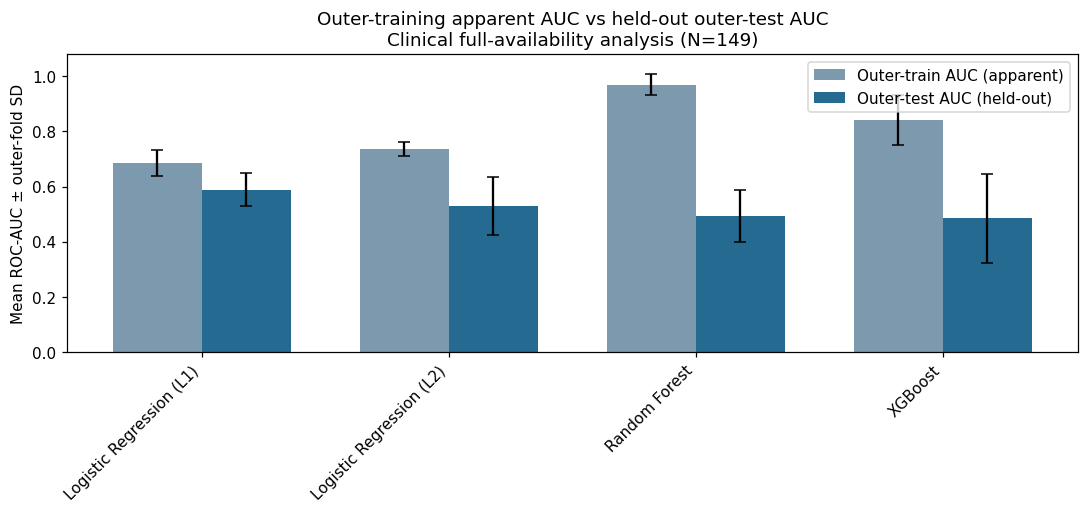

In [12]:
clinical_auc_summary = pd.read_csv(Path(output_dir) / 'clinical_train_test_comparison_reviewed.csv')
plot_clinical_apparent_heldout(clinical_auc_summary)
plt.show()


### ROC curve — Full availability (N=149)

We plot ROC curves across outer folds for each model using the saved fold-level predictions.

--- Plotting ROC Curve ---


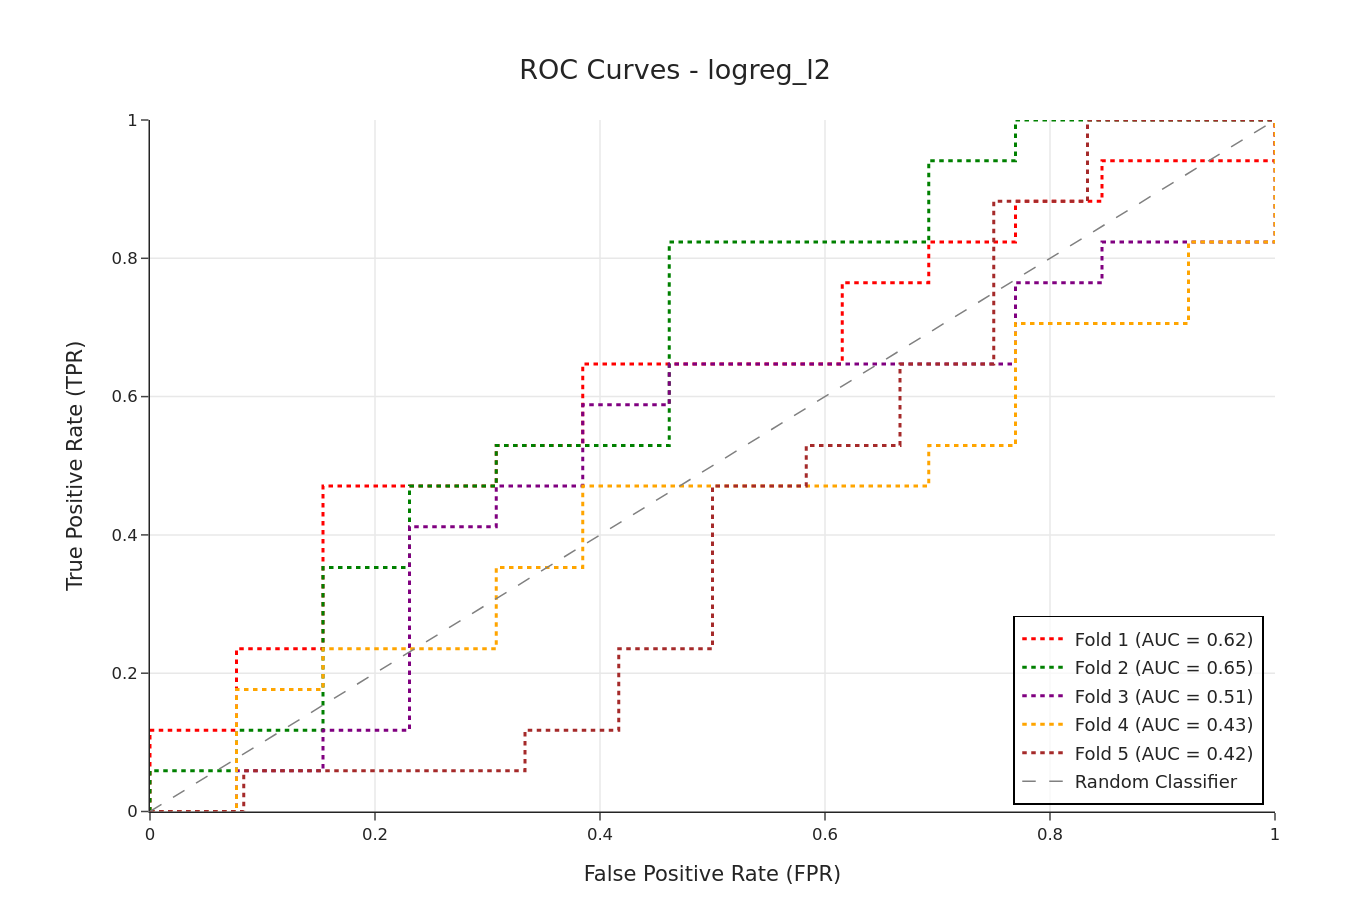

--- Plotting ROC Curve ---


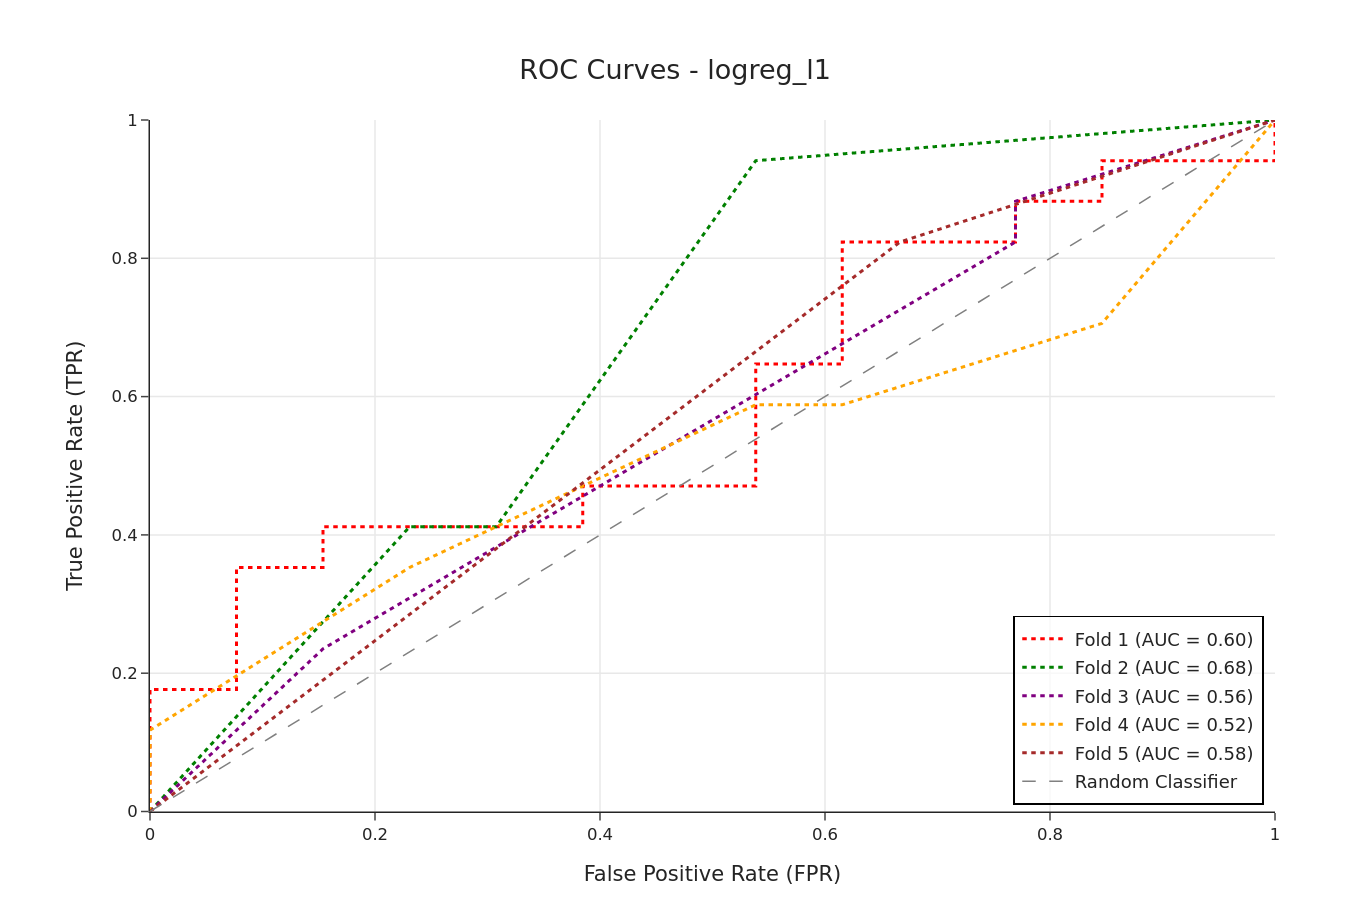

--- Plotting ROC Curve ---


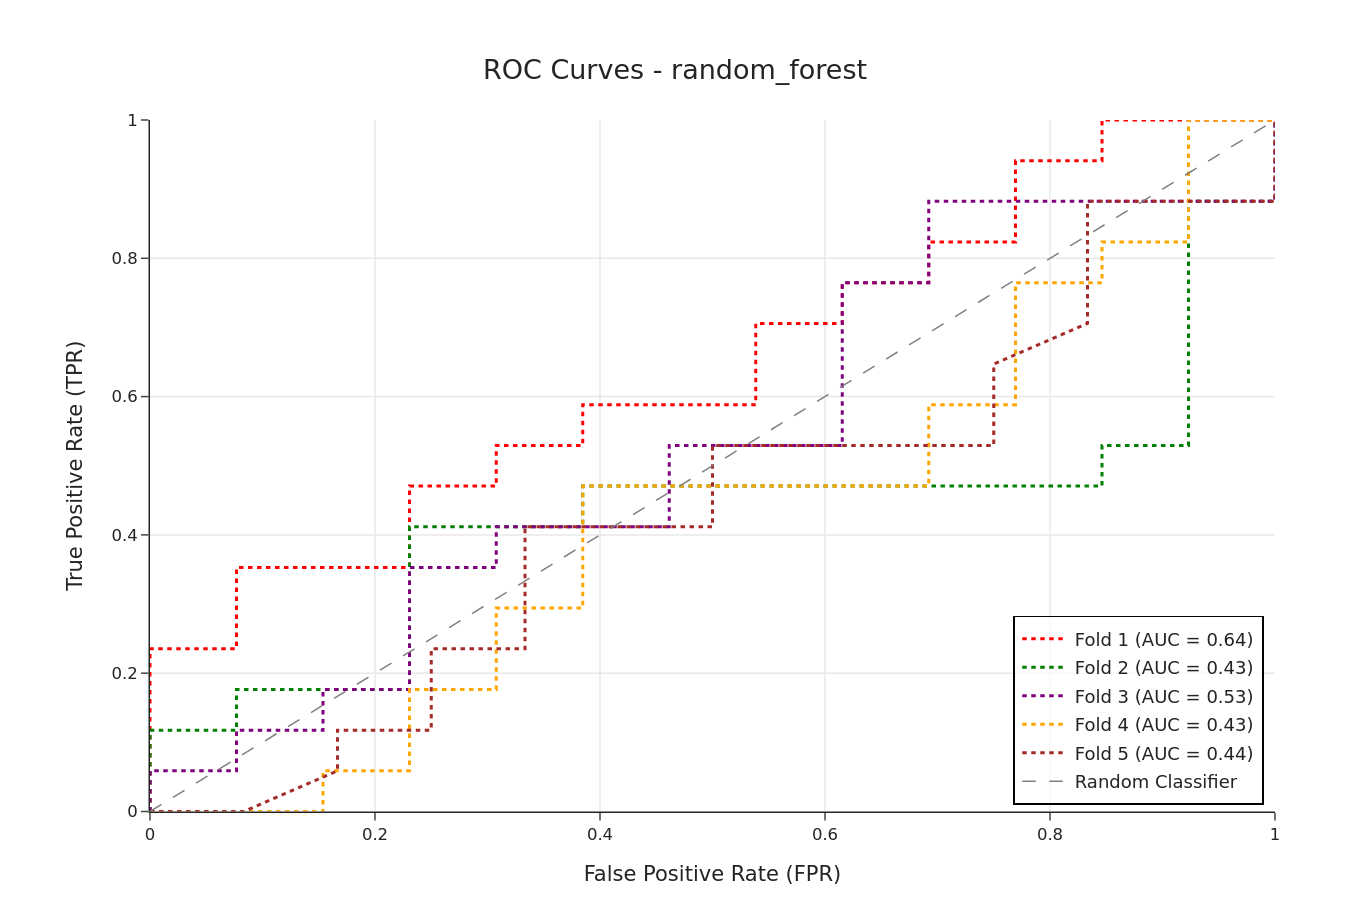

--- Plotting ROC Curve ---


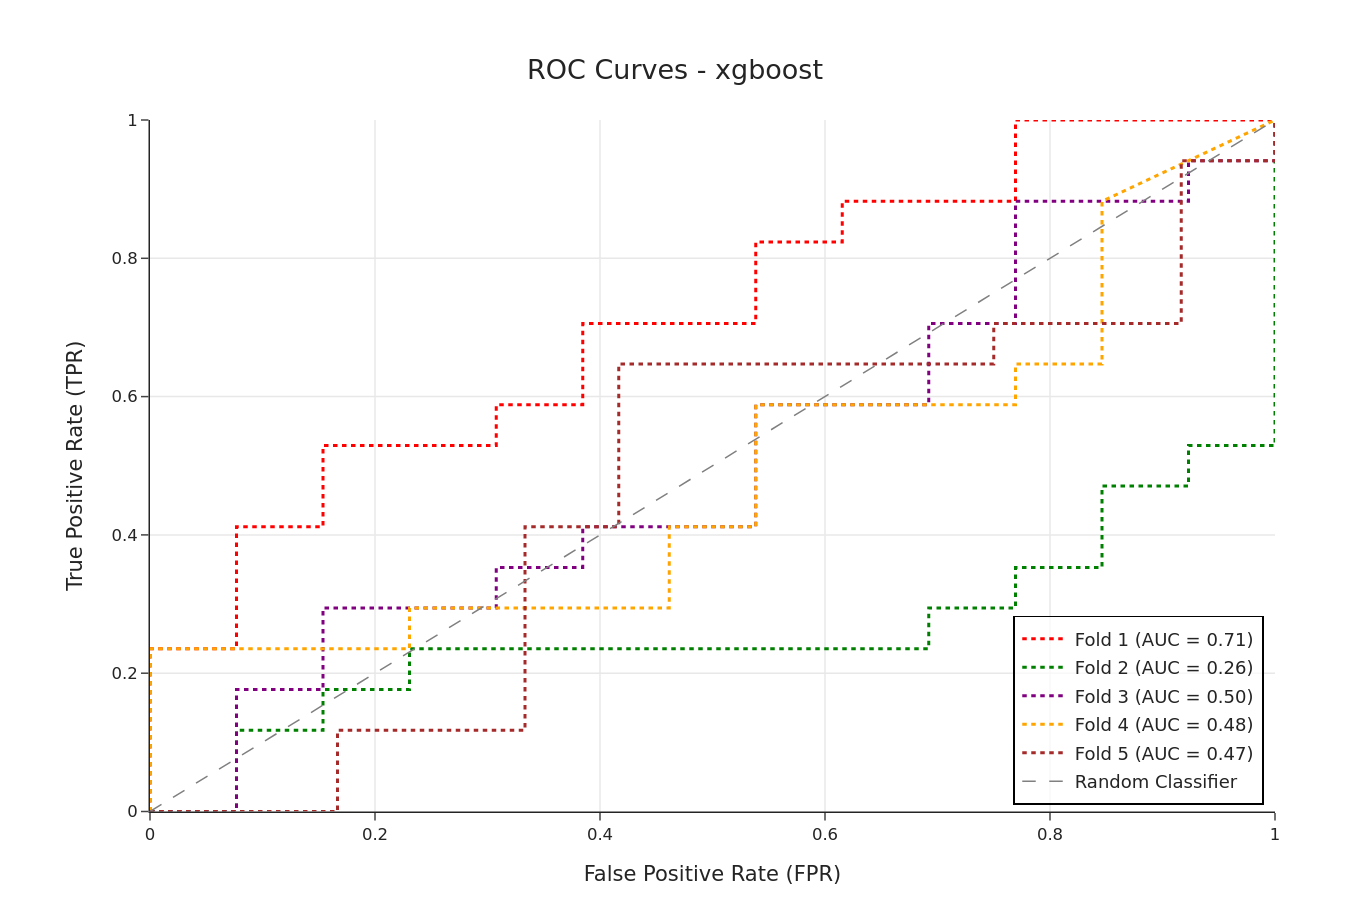

In [13]:
## Plot ROC Curves ##

for model_name in predictions_df["model"].unique():

    model_predictions_df = predictions_df[
        predictions_df["model"] == model_name
    ].copy()

    curves_data = []

    for fold_idx in sorted(model_predictions_df["outer_fold"].unique()):

        fold_predictions_df = model_predictions_df[
            model_predictions_df["outer_fold"] == fold_idx
        ]

        curves_data.append({
            "y_true": fold_predictions_df["y_true"].values,
            "y_prob": fold_predictions_df["y_proba"].values,
            "label": f"Fold {fold_idx}",
            "is_main_curve": False
        })

    plot_roc_curves(
        curves_data=curves_data,
        title=f"ROC Curves - {model_name}",
        interactive=False
    )

### ROC curve — Common cohort (N=110)

Selected-family pooled OOF predictions from the shared 110-patient comparison.

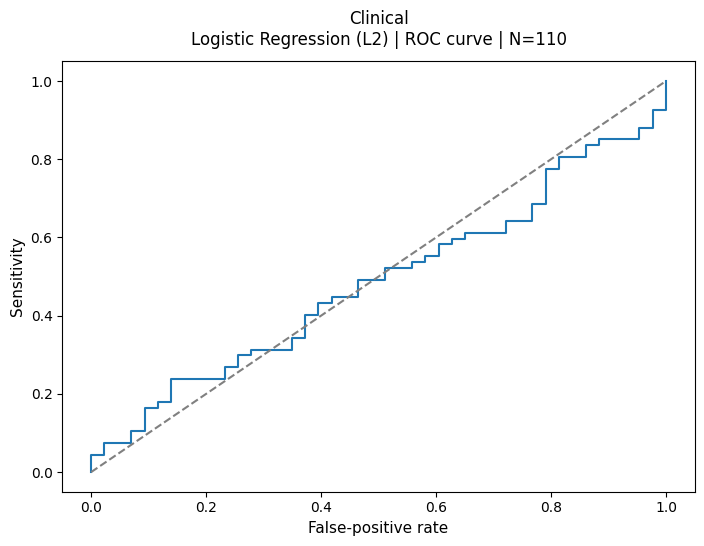

In [29]:
fig = plot_thesis_saved_figure('roc', 'clinical')
plt.show()


### Precision–Recall curve — Full availability (N=149)

Because the dataset is moderately imbalanced, precision-recall curves are reported. The curves are computed separately for each outer fold using held-out predictions only.

--- Plotting Precision–Recall Curve ---


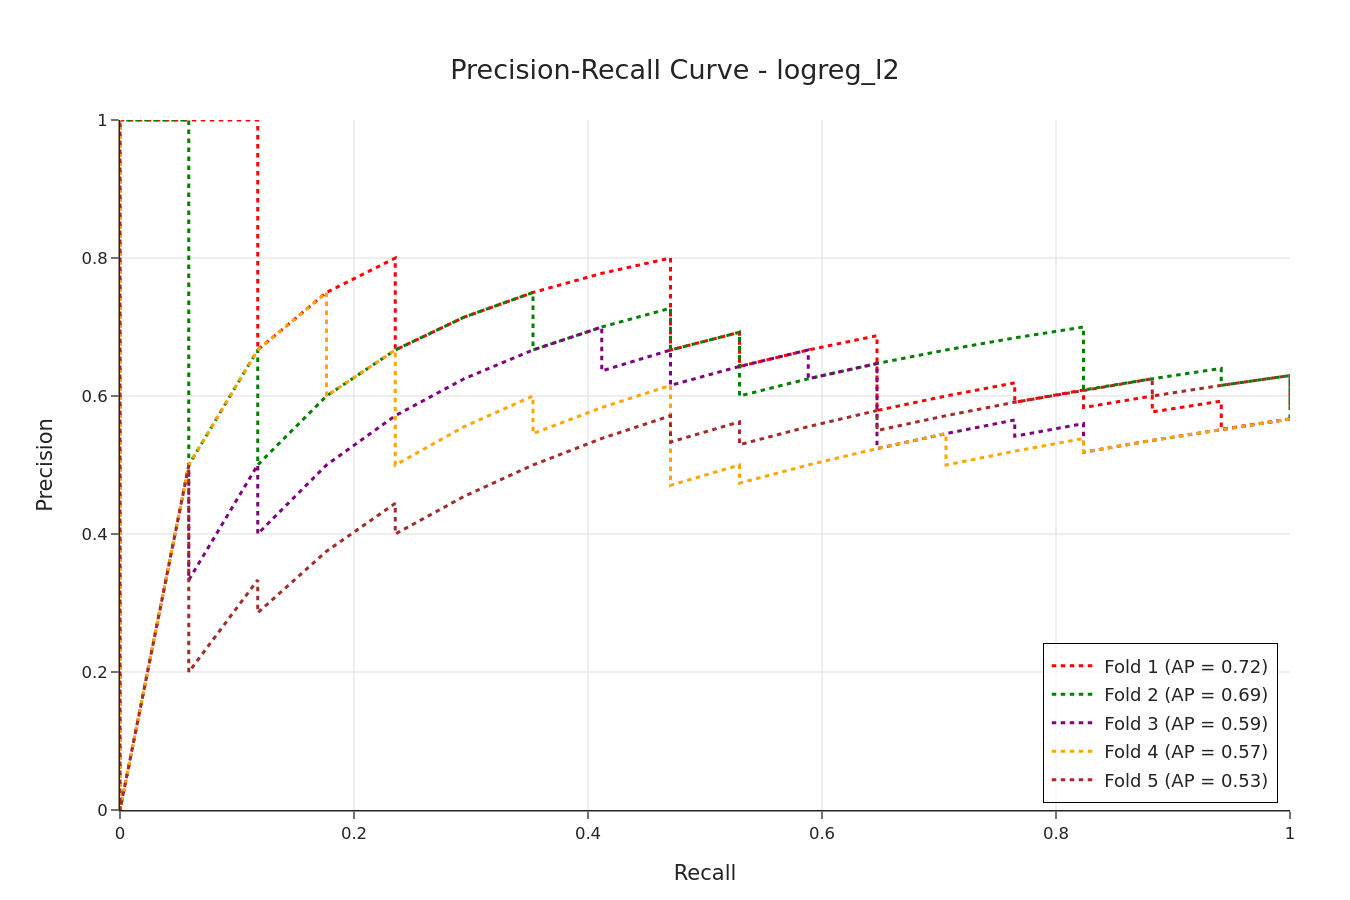

--- Plotting Precision–Recall Curve ---


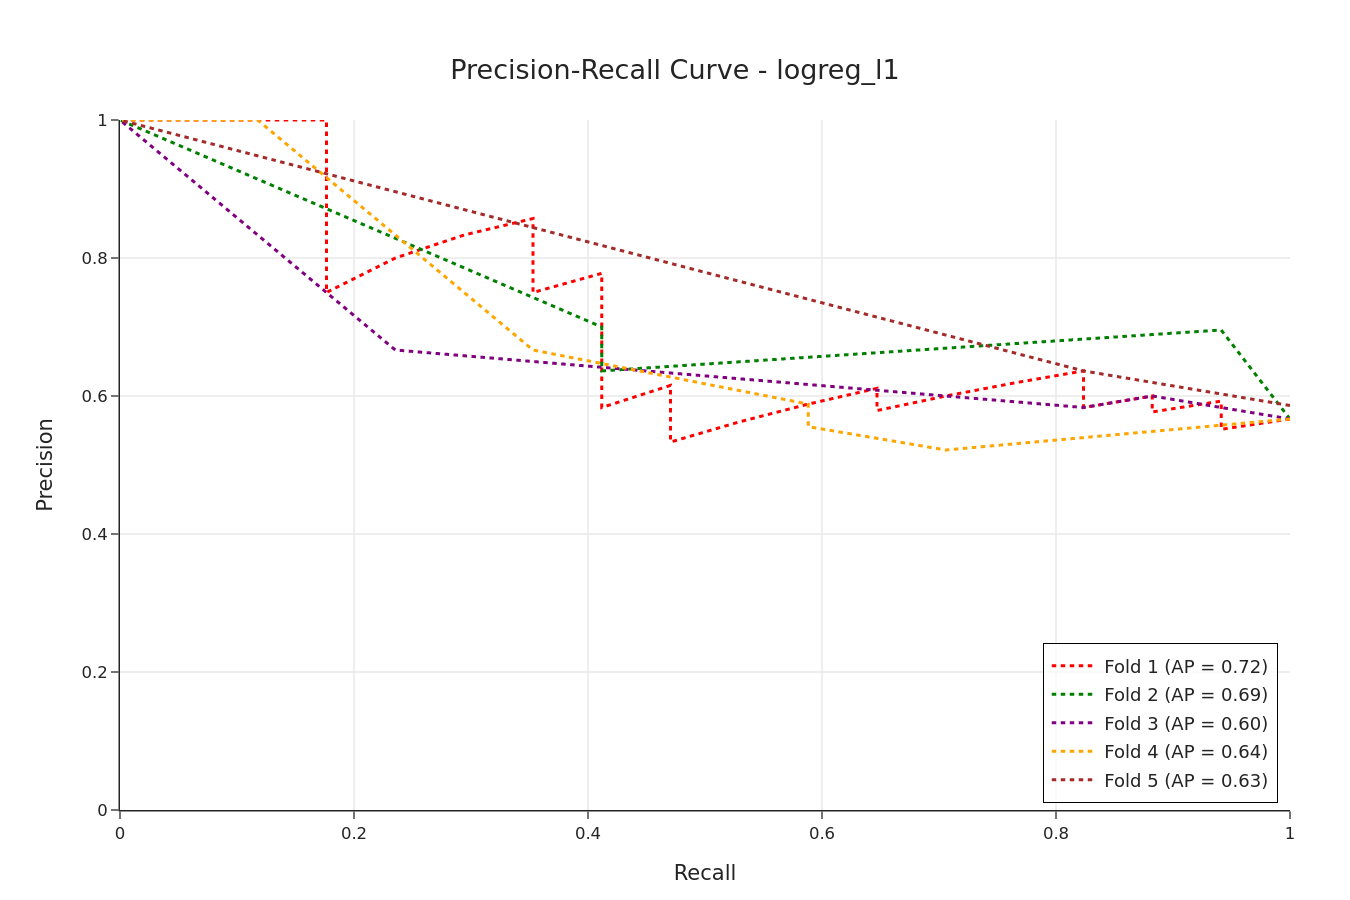

--- Plotting Precision–Recall Curve ---


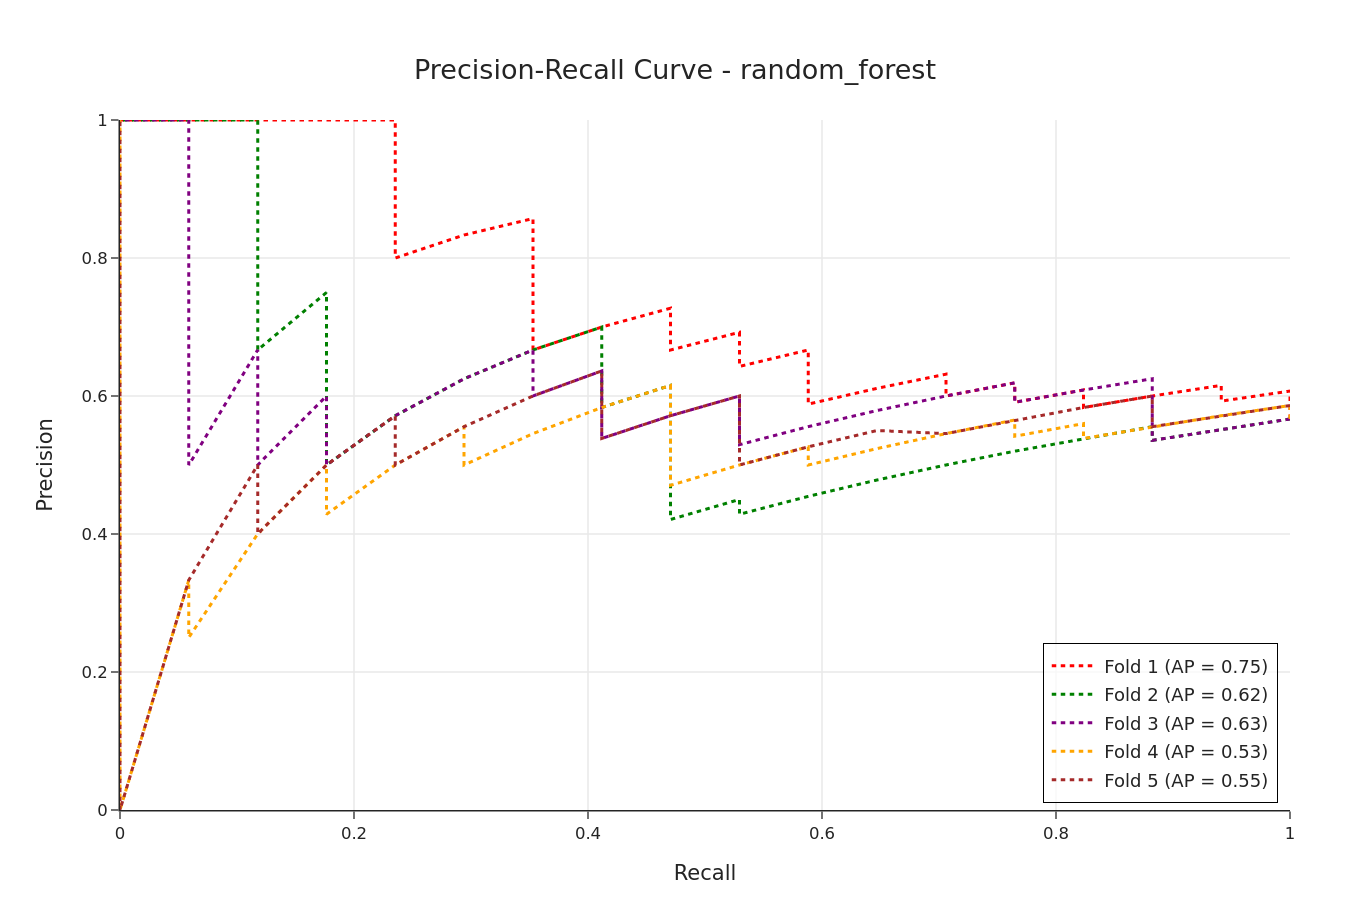

--- Plotting Precision–Recall Curve ---


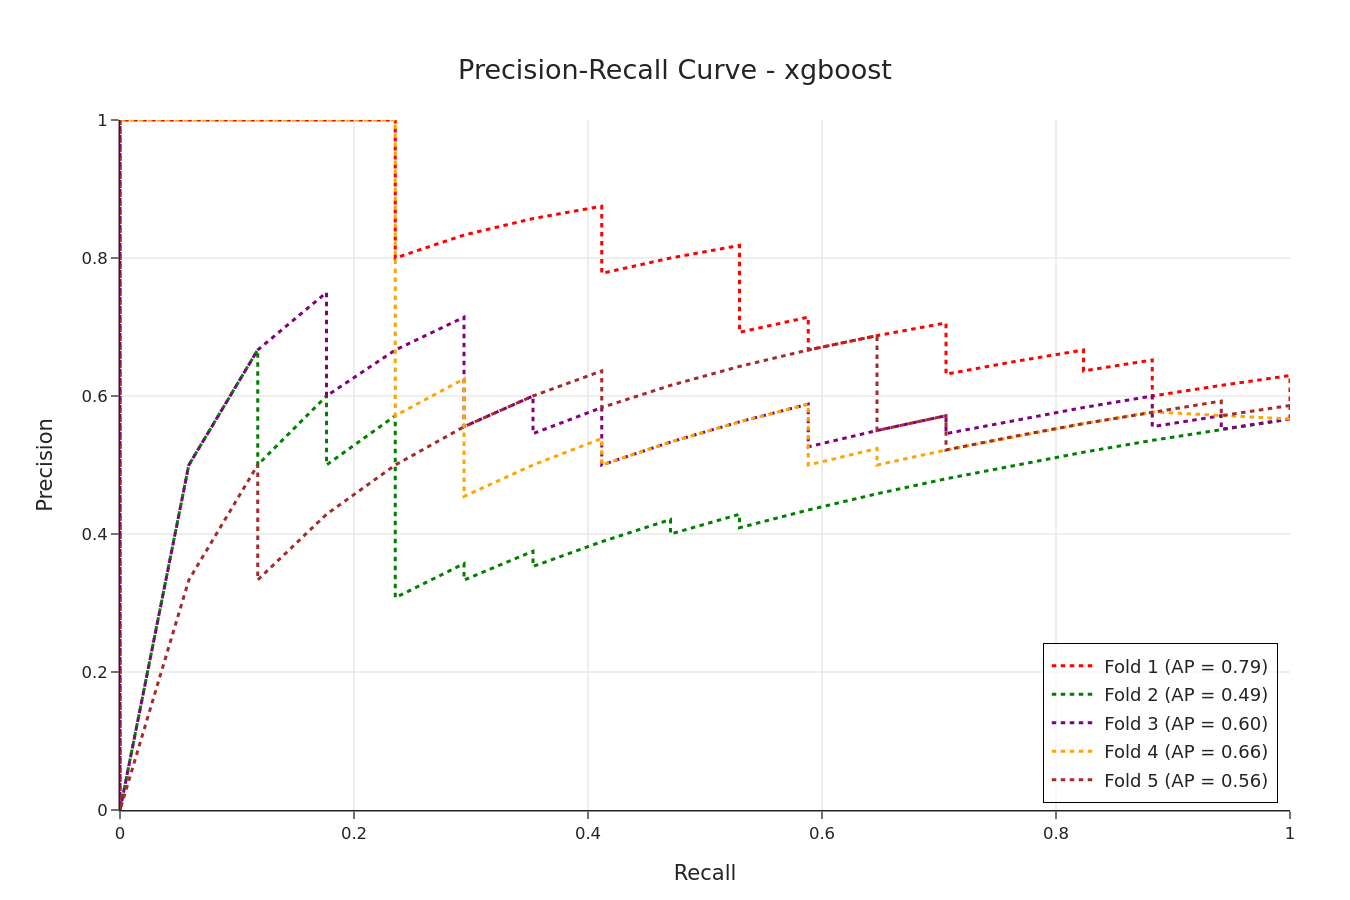

In [14]:
## Plot Precision-Recall Curves ##
for model_name in predictions_df["model"].unique():

    model_predictions_df = predictions_df[
        predictions_df["model"] == model_name
    ].copy()

    curves_data = []

    for fold_idx in sorted(model_predictions_df["outer_fold"].unique()):

        fold_predictions_df = model_predictions_df[
            model_predictions_df["outer_fold"] == fold_idx
        ]

        curves_data.append({
            "y_true": fold_predictions_df["y_true"].values,
            "y_prob": fold_predictions_df["y_proba"].values,
            "label": f"Fold {fold_idx}",
            "is_main_curve": False
        })

    plot_precision_recall_curves(
        curves_data=curves_data,
        title=f"Precision-Recall Curve - {model_name}",
        interactive=False
    )

### Precision–Recall curve — Common cohort (N=110)

Selected-family pooled OOF predictions from the shared 110-patient comparison.

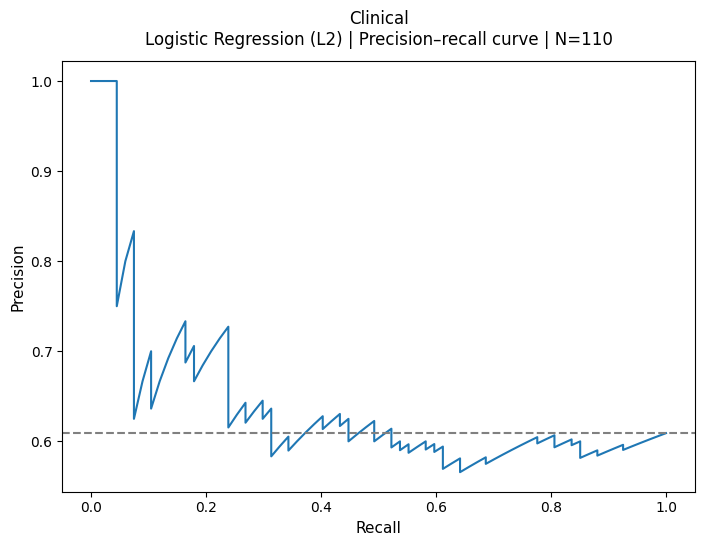

In [30]:
fig = plot_thesis_saved_figure('pr', 'clinical')
plt.show()


### Confusion matrix — Full availability (N=149)

These confusion matrices compare error patterns across the candidate model families: Logistic Regression L1, Logistic Regression L2, Random Forest, and XGBoost. Each matrix pools that family's existing validated held-out outer-fold predictions, with one prediction per patient. This is a secondary comparison diagnostic and does not determine model selection.

The pooled OOF section below shows a single confusion matrix for the family selected by the predefined mean inner-CV macro-F1 criterion. That family also appears in this per-family comparison.


--- Plotting Confusion Matrix ---


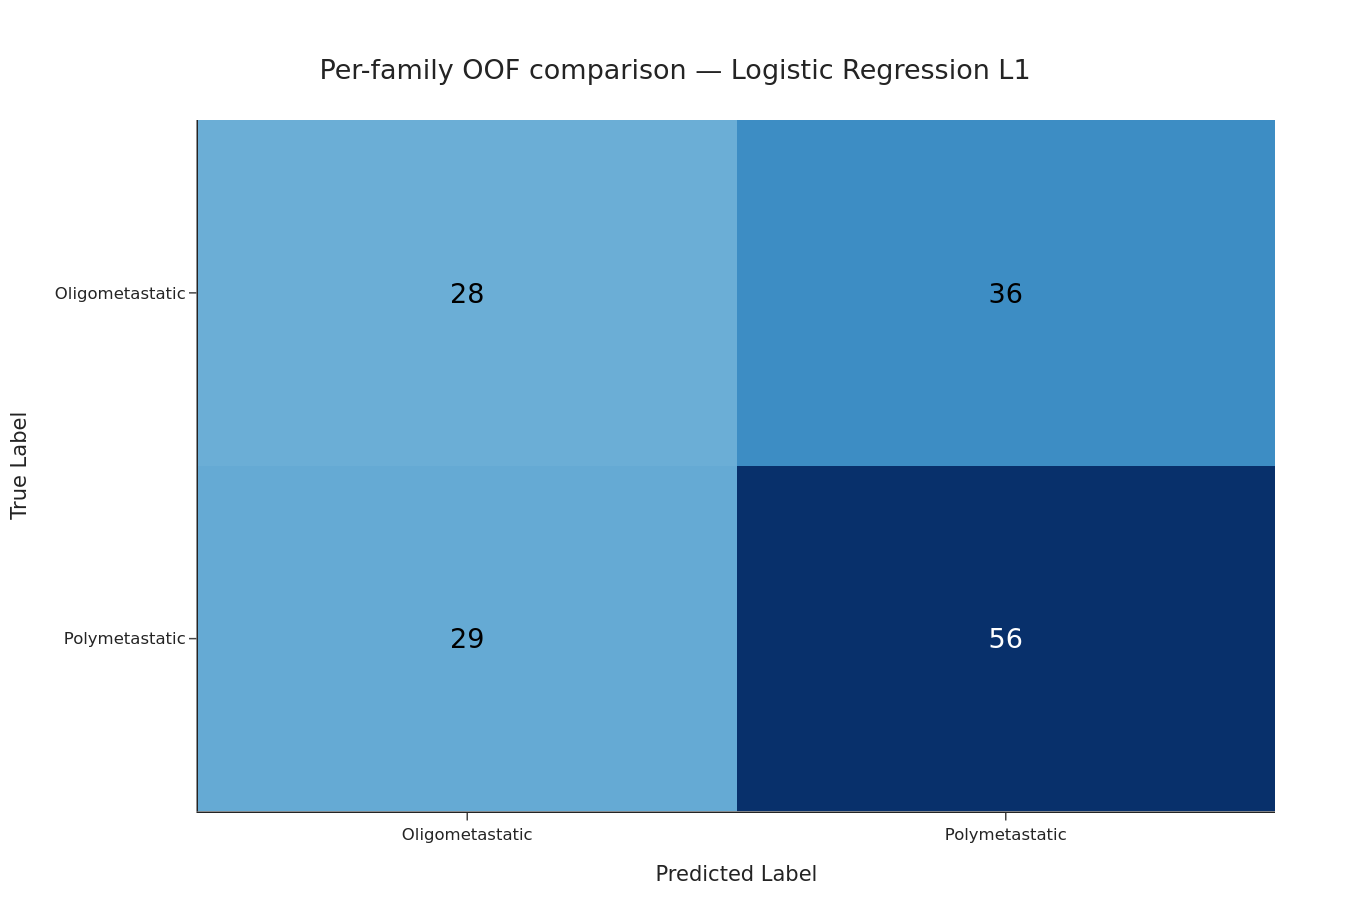

--- Plotting Confusion Matrix ---


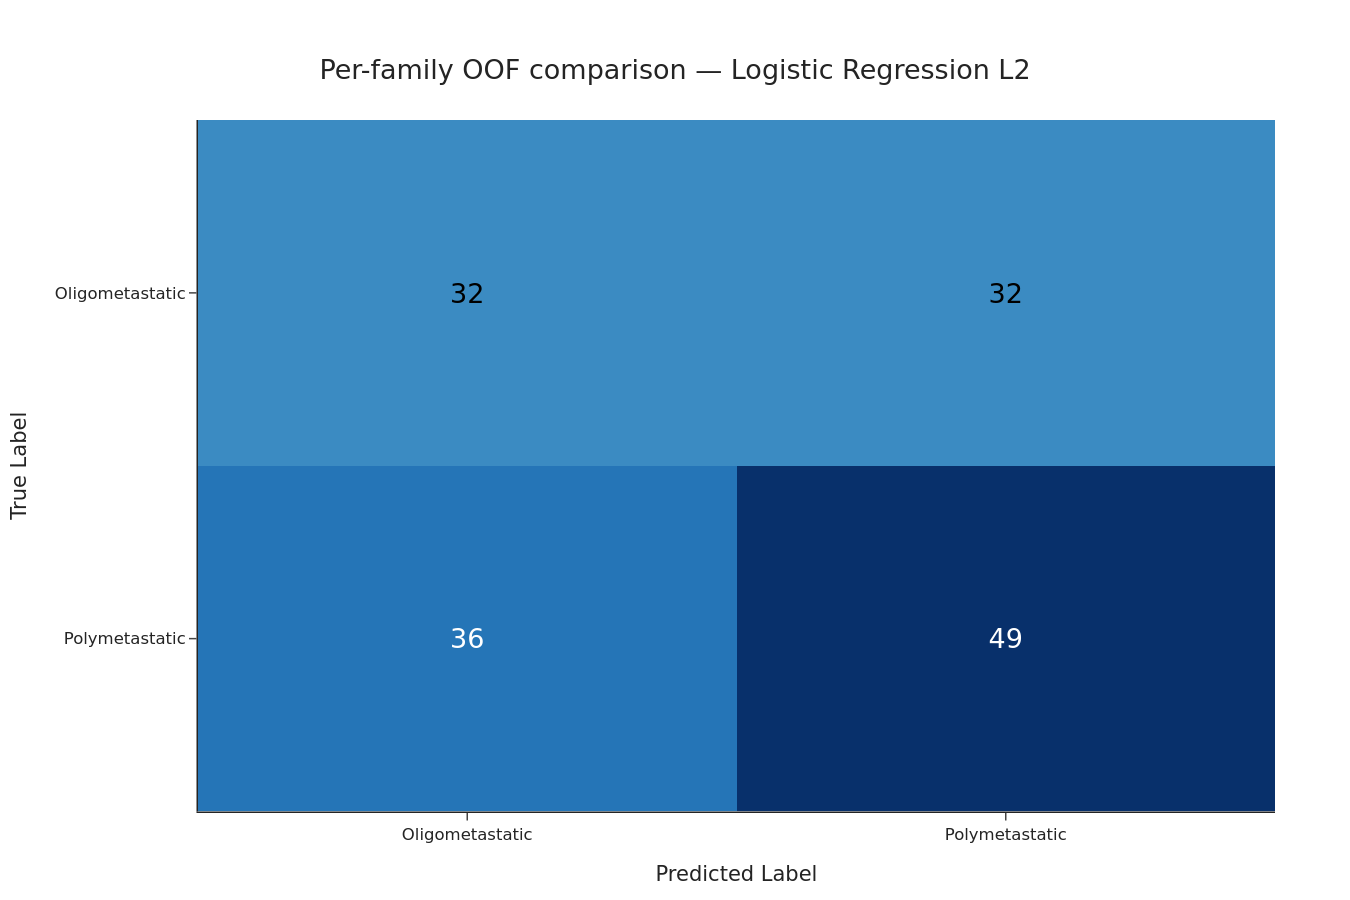

--- Plotting Confusion Matrix ---


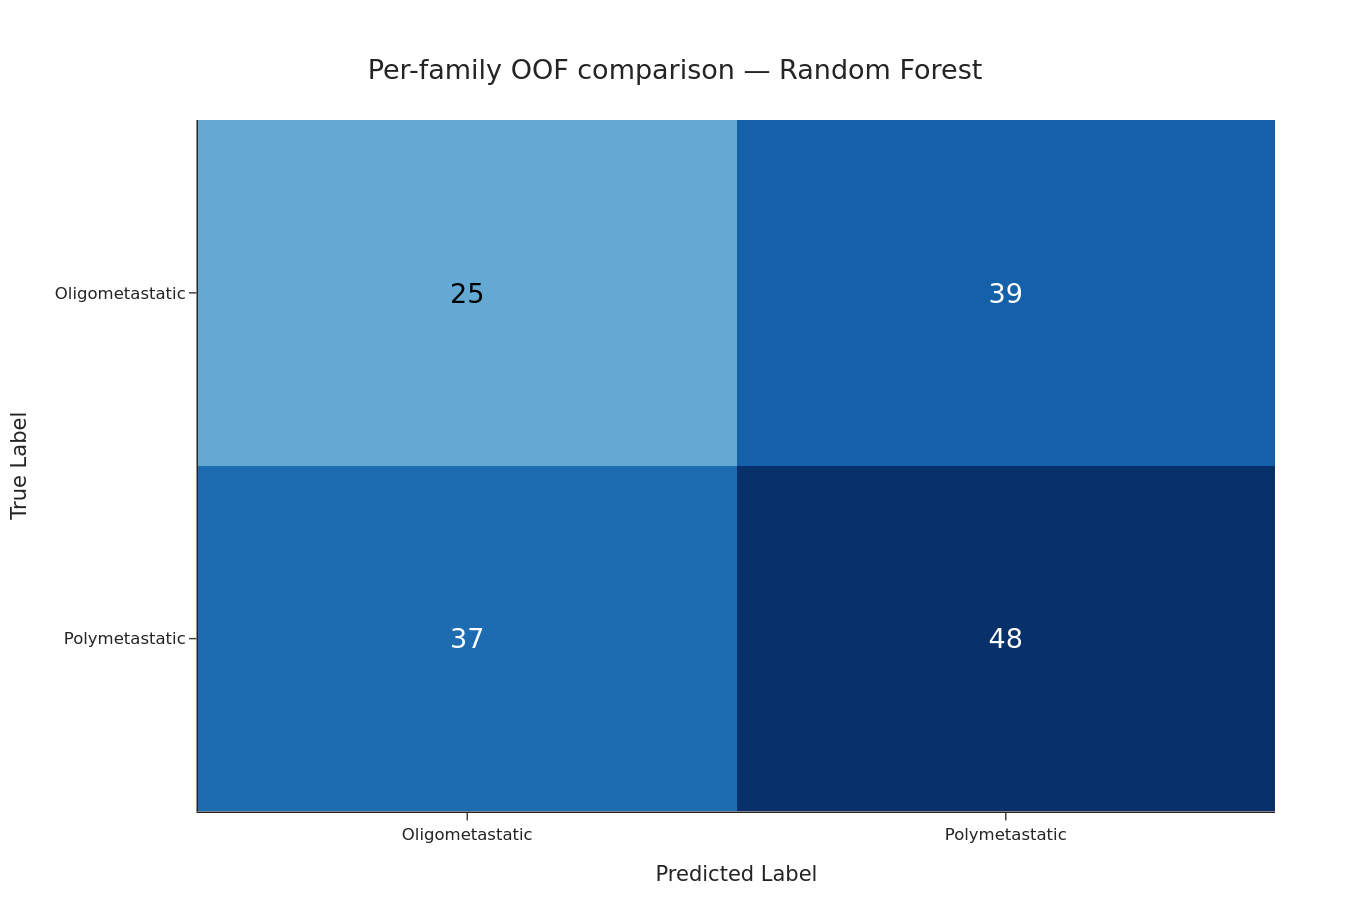

--- Plotting Confusion Matrix ---


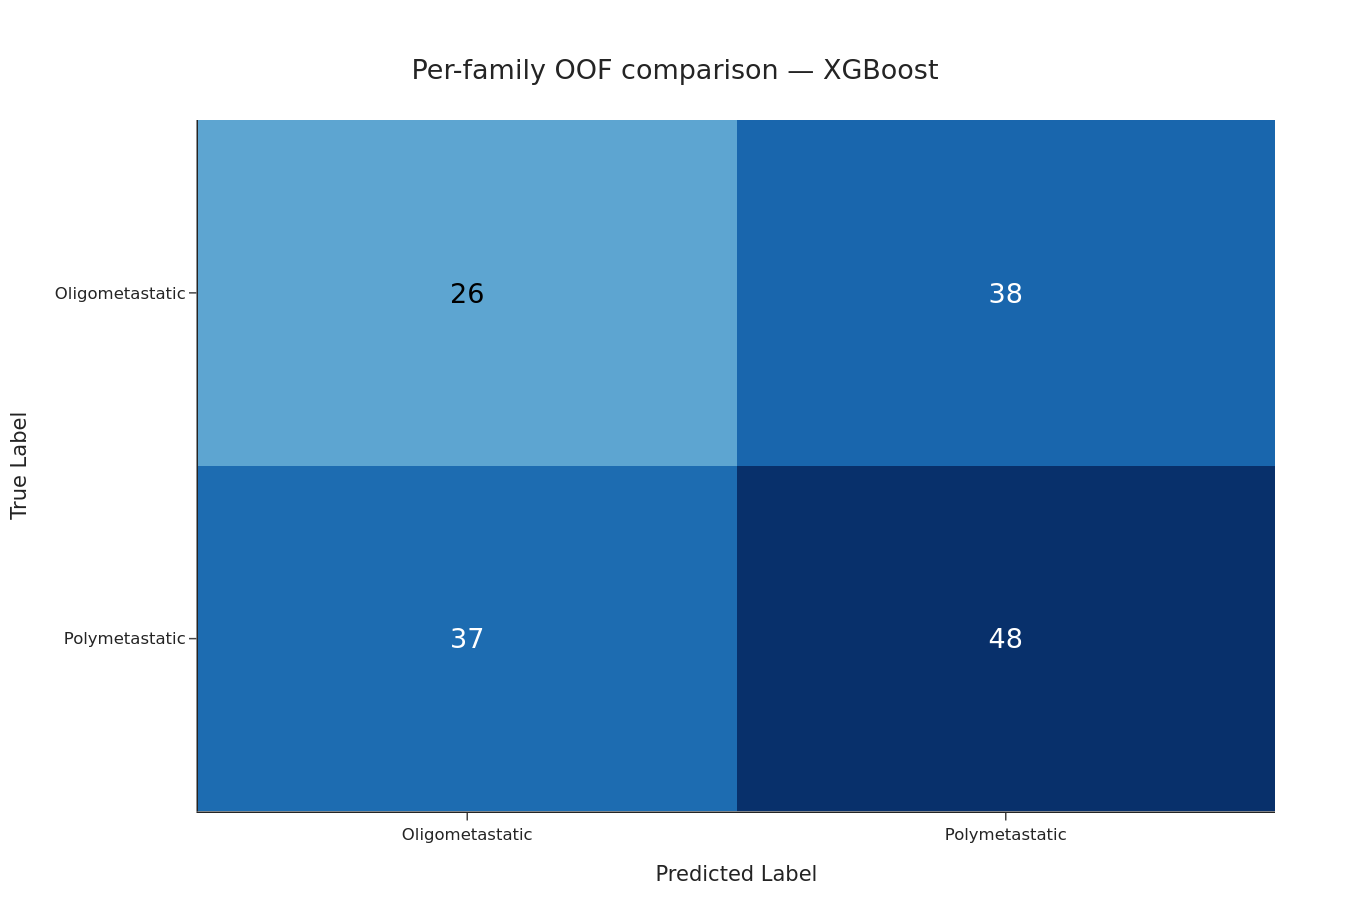

In [15]:
# Reuse validated OOF predictions loaded from the existing saved results.
confusion_matrix_family_labels = {
    "logreg_l1": "Logistic Regression L1",
    "logreg_l2": "Logistic Regression L2",
    "random_forest": "Random Forest",
    "xgboost": "XGBoost",
}
for family_name, family_label in confusion_matrix_family_labels.items():
    family_oof_df = validated_oof_by_model[family_name]
    plot_confusion_matrix(
        family_oof_df["y_true"],
        family_oof_df["y_pred"],
        class_labels=["Oligometastatic", "Polymetastatic"],
        title=f"Per-family OOF comparison — {family_label}",
        interactive=False,
    )


### Confusion matrix — Common cohort (N=110)

Selected-family pooled OOF predictions from the shared 110-patient comparison.

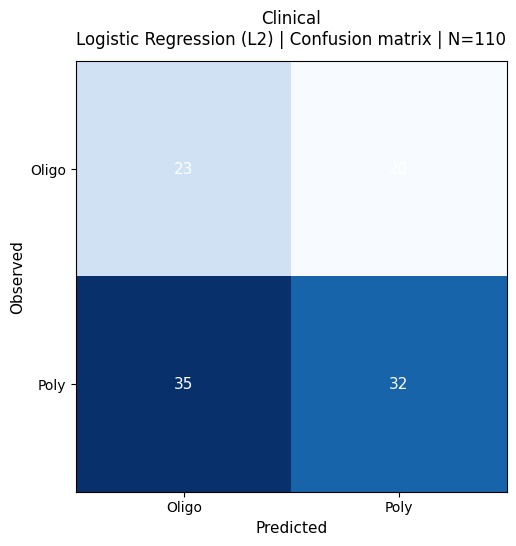

In [31]:
fig = plot_thesis_saved_figure('confusion_matrix', 'clinical')
plt.show()


## Select the Best Model Using Inner-Cross-Validation Macro-F1 Scores

For each candidate model family, hyperparameters are selected within the inner cross-validation loop using only the training data from each outer fold.

The final model family used for refitting and interpretation is selected according to the mean inner-cross-validation macro-F1 score across outer folds.

Outer-fold test metrics are displayed alongside the inner-cross-validation scores to estimate out-of-training performance, but they are not used for model selection.

In [16]:
model_selection_summary = (
    report_test_df
    .groupby("model")
    .agg(
        mean_inner_cv_score=("best_inner_score", "mean"),
        std_inner_cv_score=("best_inner_score", "std"),
        mean_test_auc_score=("auc_score", "mean"),
        mean_test_accuracy=("accuracy", "mean"),
        mean_test_balanced_accuracy=("balanced_accuracy", "mean"),
        mean_test_f1_score=("f1_score", "mean"),
        mean_test_precision=("precision", "mean"),
        mean_test_sensitivity=("sensitivity", "mean"),
        mean_test_specificity=("specificity", "mean")
    )
    .sort_values(by="mean_inner_cv_score", ascending=False)
)

# Validate complete inner-score coverage; ranks never use outer-test metrics.
inner_fold_ranking_df, model_fold_wins_df = rank_clinical_inner_scores(
    results_test_df, list(models), n_outer_folds=len(outer_splits)
)
for metric in metric_cols + ["macro_f1", "average_precision", "brier_score"]:
    model_selection_summary[f"std_test_{metric}"] = report_test_df.groupby("model")[metric].std()
    if f"mean_test_{metric}" not in model_selection_summary:
        model_selection_summary[f"mean_test_{metric}"] = report_test_df.groupby("model")[metric].mean()
# Deterministic alphabetical tie-break; no outer-test metric enters this ordering.
model_selection_summary = model_selection_summary.sort_index().sort_values(
    "mean_inner_cv_score", ascending=False, kind="stable"
)
thesis_print("Model selection summary (arithmetic mean and sample SD across five outer folds):")
thesis_display(model_selection_summary)

selected_model_name = model_selection_summary.index[0]

# Keep this alias to avoid renaming all downstream variables and output files.
best_model_name = selected_model_name

thesis_print(
    "Selected model based on mean inner-cross-validation score:",
    selected_model_name
)

thesis_print(
    "Outer-fold test metrics are reported only for out-of-training "
    "performance estimation, not for model selection."
)

model_selection_summary.to_csv(
    os.path.join(output_dir, "clinical_model_selection_summary_reviewed.csv")
)

Model selection summary (arithmetic mean and sample SD across five outer folds):


,mean_inner_cv_score,std_inner_cv_score,mean_test_auc_score,mean_test_accuracy,mean_test_balanced_accuracy,mean_test_f1_score,mean_test_precision,mean_test_sensitivity,mean_test_specificity,std_test_auc_score,...,std_test_f1_score,std_test_precision,std_test_sensitivity,std_test_specificity,std_test_macro_f1,mean_test_macro_f1,std_test_average_precision,mean_test_average_precision,std_test_brier_score,mean_test_brier_score
model,,,,,,,,,,,,,,,,,,,,,
xgboost,0.587,0.043,0.485,0.497,0.487,0.565,0.572,0.565,0.409,0.162,...,0.062,0.101,0.032,0.247,0.144,0.478,0.114,0.622,0.052,0.284
random_forest,0.581,0.032,0.493,0.490,0.477,0.546,0.550,0.565,0.390,0.094,...,0.109,0.047,0.184,0.209,0.075,0.459,0.087,0.616,0.026,0.270
logreg_l2,0.560,0.028,0.529,0.543,0.537,0.577,0.599,0.576,0.497,0.106,...,0.131,0.064,0.192,0.152,0.090,0.528,0.080,0.621,0.020,0.255
logreg_l1,0.555,0.038,0.589,0.564,0.547,0.624,0.611,0.659,0.436,0.059,...,0.085,0.025,0.174,0.173,0.027,0.536,0.048,0.656,0.009,0.249


Selected model based on mean inner-cross-validation score: xgboost
Outer-fold test metrics are reported only for out-of-training performance estimation, not for model selection.


### Model-family selection stability

Within each outer fold, candidate families are ranked from highest to lowest `best_inner_score` (inner-CV macro-F1). This shows how stable model-family selection is when the training data change. Exact ties are resolved alphabetically, both within folds and for the mean-inner-score family choice; outer-test metrics never break ties. Fold win counts are descriptive and do not replace the predefined mean-inner-score selection criterion.

The current clinical results select XGBoost (mean inner macro-F1 0.5873), followed by Random Forest (0.5813), L2 logistic regression (0.5596), and L1 logistic regression (0.5549). XGBoost wins three folds, Random Forest one, and L1 logistic regression one.

In [17]:
thesis_display(inner_fold_ranking_df)
thesis_display(model_fold_wins_df)
inner_fold_ranking_df.to_csv(Path(output_dir) / "clinical_inner_fold_ranking_reviewed.csv", index=False)
model_fold_wins_df.to_csv(Path(output_dir) / "clinical_model_fold_wins_reviewed.csv")

,outer_fold,model,best_inner_score,rank,is_winner
0,1,random_forest,0.545,1,True
1,1,logreg_l2,0.543,2,False
2,1,xgboost,0.529,3,False
3,1,logreg_l1,0.497,4,False
4,2,xgboost,0.626,1,True
5,2,random_forest,0.600,2,False
6,2,logreg_l1,0.544,3,False
7,2,logreg_l2,0.543,4,False
8,3,xgboost,0.593,1,True
9,3,logreg_l1,0.567,2,False


,outer_fold_wins
model,
logreg_l2,0
logreg_l1,1
random_forest,1
xgboost,3


### Family selection in both contexts

The selected family in each column is determined by the highest mean inner-CV macro-F1. Values summarise five outer folds. The common-cohort (N=110) protocol uses compact common-cohort grids, inner/outer training-local preprocessing, seeded MI, no resampling and fit-local XGBoost weighting.

In [4]:
p110_selection_file = p110_prefix + ('_representation' if p110_config == 'transcriptomics' else '') + '_model_selection_summary_reviewed.csv'
p110_secondary_selection = p110_pd.read_csv(p110_root.parent / p110_folder / p110_selection_file)
p110_key = 'representation' if p110_config == 'transcriptomics' else 'model'
if p110_config == 'transcriptomics':
    p110_secondary_selection = p110_secondary_selection[p110_secondary_selection.representation.str.startswith('gene_level_')].copy()
p110_secondary_selection['family'] = p110_secondary_selection[p110_key].str.replace('gene_level_', '', regex=False)
p110_primary_selection = p110_bundle['ranking'].query('configuration == @p110_config').copy()
p110_selection_comparison = p110_secondary_selection[['family','mean_inner_cv_score','std_inner_cv_score']].merge(
    p110_primary_selection[['family','mean_inner_macro_f1','std_inner_macro_f1']],on='family',how='outer',validate='one_to_one')
p110_selection_comparison['Selected — '+p110_secondary_label] = p110_selection_comparison.family.eq(p110_secondary_family.removeprefix('gene_level_'))
p110_selection_comparison['Selected — '+p110_primary_label] = p110_selection_comparison.family.eq(p110_primary_family)
p110_selection_comparison = p110_selection_comparison.rename(columns={
    'mean_inner_cv_score':p110_secondary_label+' mean inner macro-F1',
    'std_inner_cv_score':p110_secondary_label+' SD',
    'mean_inner_macro_f1':p110_primary_label+' mean inner macro-F1',
    'std_inner_macro_f1':p110_primary_label+' SD'})
thesis_display(p110_selection_comparison.fillna('—'))

,family,Full availability (N=149) mean inner macro-F1,Full availability (N=149) SD,Common cohort (N=110) mean inner macro-F1,Common cohort (N=110) SD,Selected — Full availability (N=149),Selected — Common cohort (N=110)
0,logreg_l1,0.555,0.038,0.528,0.079,False,False
1,logreg_l2,0.560,0.028,0.557,0.066,False,True
2,random_forest,0.581,0.032,0.530,0.032,False,False
3,xgboost,0.587,0.043,0.517,0.025,True,False


### Pooled out-of-fold evaluation of the selected family

Mean outer-fold metrics average the metric calculated independently in each fold. Pooled OOF metrics calculate the metric once after concatenating all held-out predictions, with every patient contributing exactly once. The two summaries answer different questions and need not be numerically identical.

ROC-AUC, average precision (AP) and Brier score use probabilities of polymetastatic disease; balanced accuracy, macro-F1, precision, sensitivity and specificity use predicted classes. AP summarises the precision–recall curve using recall increments, rather than trapezoidal integration. The ROC curve, PR curve and main confusion matrix below use only the validated OOF predictions.

Outer-test results estimate how each prespecified family generalises after inner hyperparameter tuning. Choosing one family by its mean inner score across all outer folds adds a further selection step, so the displayed OOF result is not an independent validation of that choice. No outer-test metric is used to choose the family.

,model,metric,pooled_oof_value,n_patients
0,xgboost,ROC-AUC,0.474,149
1,xgboost,Balanced accuracy,0.485,149
2,xgboost,Macro-F1,0.485,149
3,xgboost,Precision (polymetastatic = 1),0.558,149
4,xgboost,Sensitivity (polymetastatic = 1),0.565,149
5,xgboost,Specificity (oligometastatic = 0),0.406,149
6,xgboost,Average precision (PR),0.544,149
7,xgboost,Brier score,0.284,149


--- Plotting ROC Curve ---


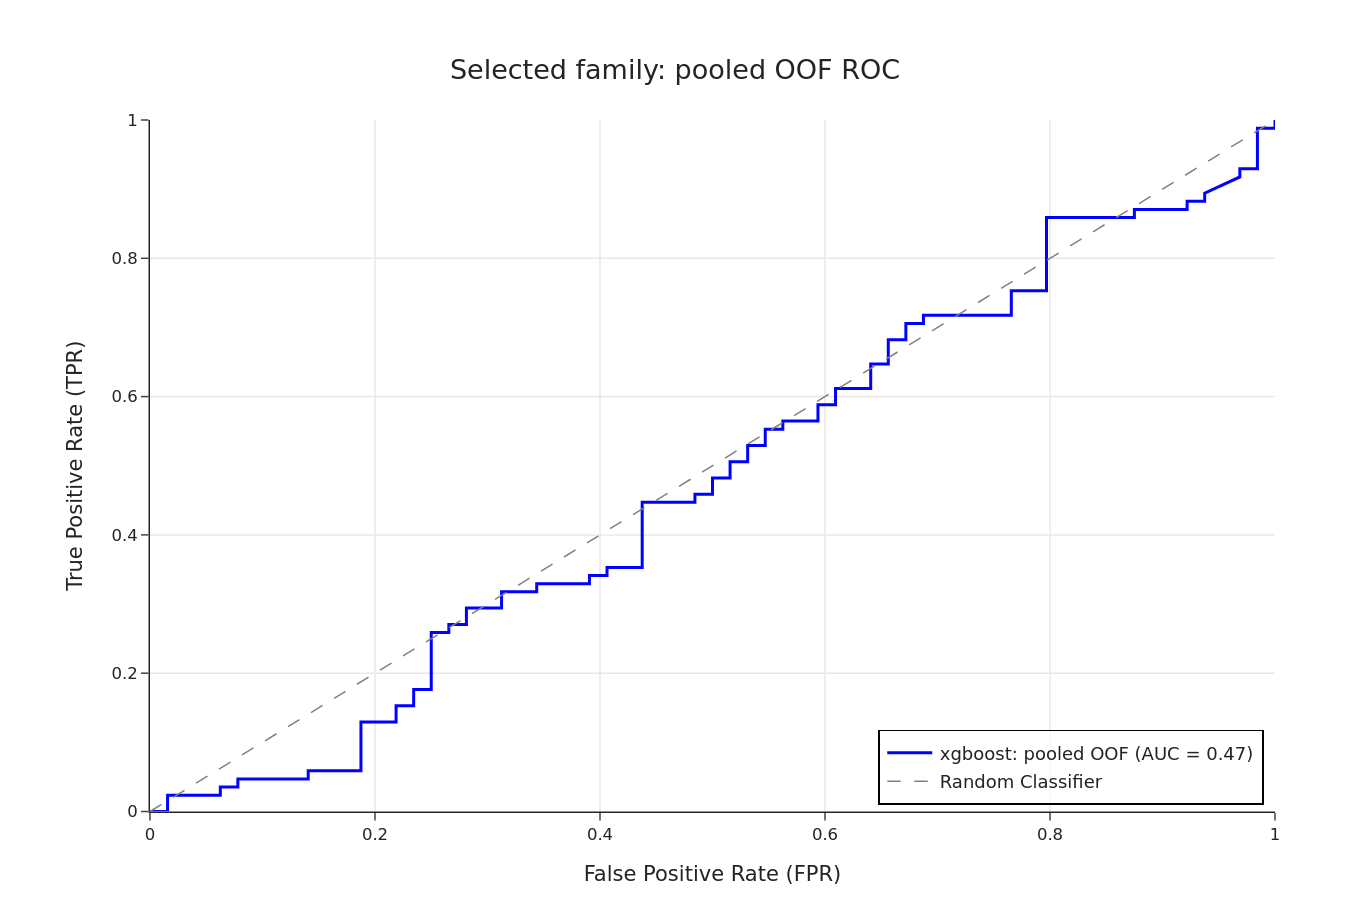

--- Plotting Precision–Recall Curve ---


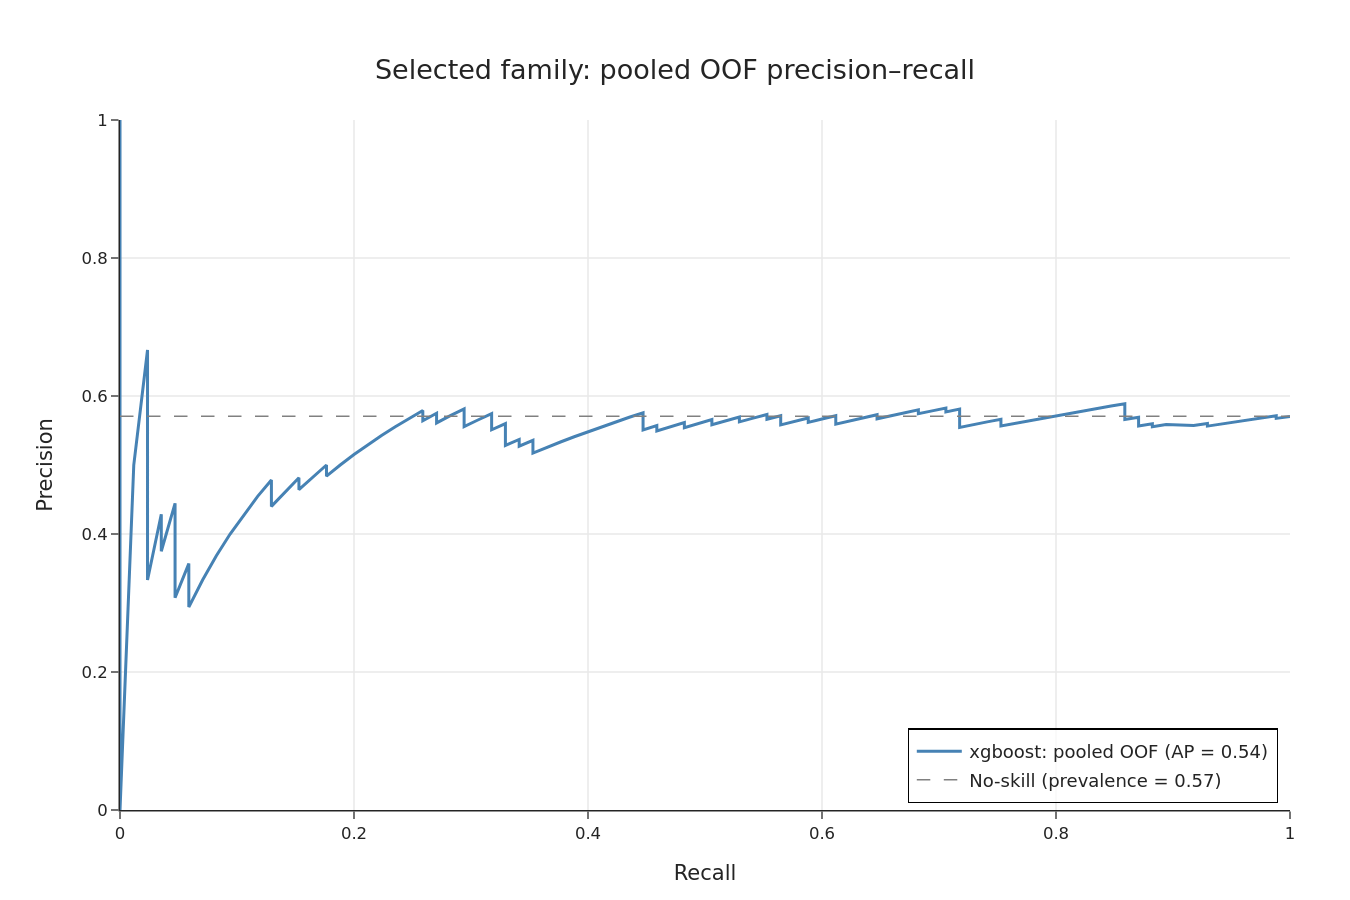

--- Plotting Confusion Matrix ---


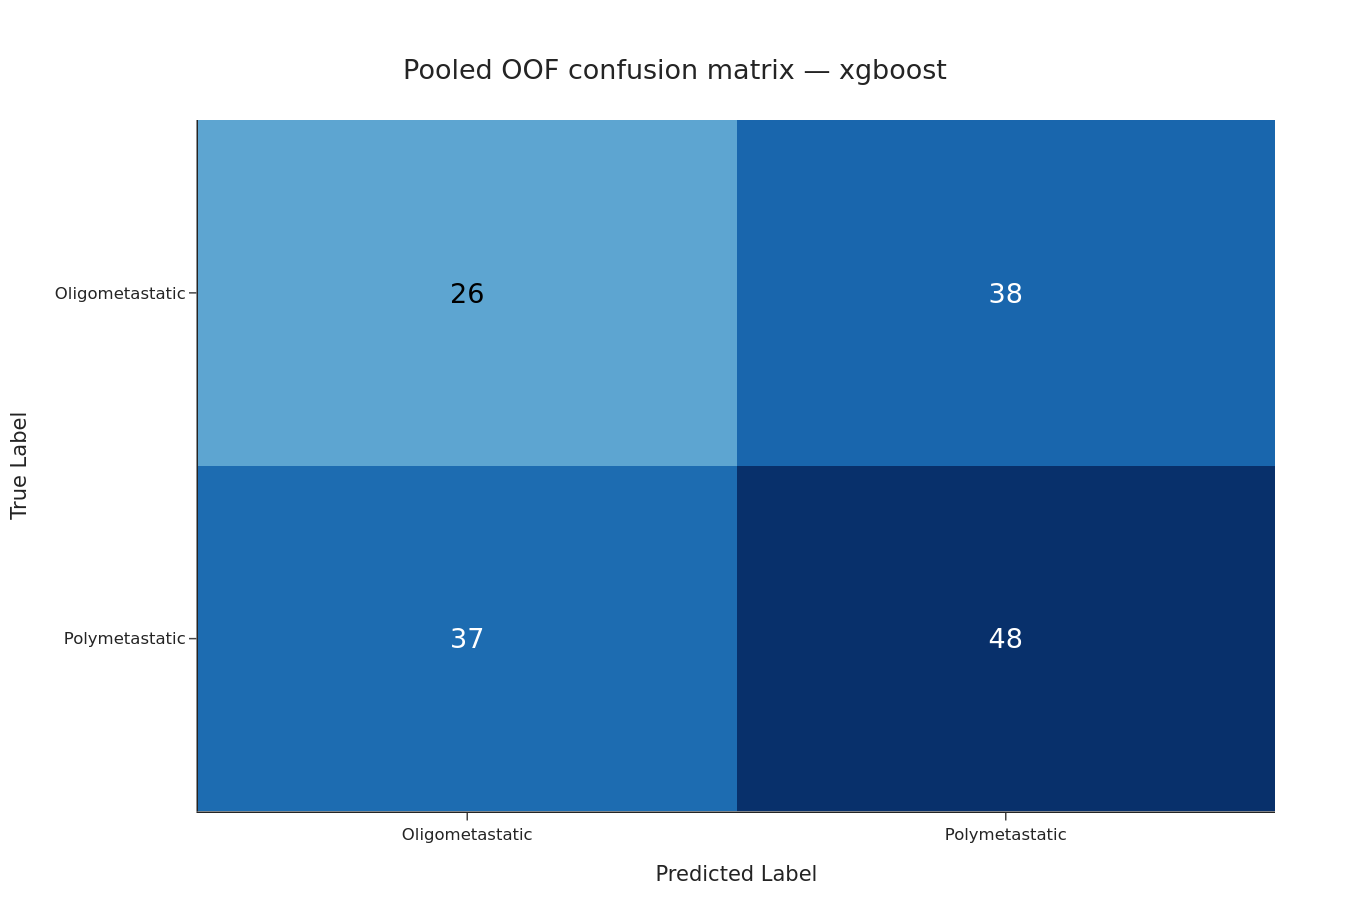

In [18]:
selected_oof_df = validated_oof_by_model[selected_model_name]
pooled_metrics = clinical_binary_metrics(selected_oof_df.y_true, selected_oof_df.y_pred, selected_oof_df.y_proba)
pooled_metric_labels = {
    "auc_score": "ROC-AUC", "balanced_accuracy": "Balanced accuracy", "macro_f1": "Macro-F1",
    "precision": "Precision (polymetastatic = 1)", "sensitivity": "Sensitivity (polymetastatic = 1)",
    "specificity": "Specificity (oligometastatic = 0)",
    "average_precision": "Average precision (PR)", "brier_score": "Brier score",
}
pooled_oof_metrics_df = pd.DataFrame([
    {"model": selected_model_name, "metric": label, "pooled_oof_value": pooled_metrics[key],
     "n_patients": len(selected_oof_df)} for key, label in pooled_metric_labels.items()
])
thesis_display(pooled_oof_metrics_df)
pooled_oof_metrics_df.to_csv(Path(output_dir) / "clinical_selected_pooled_oof_metrics_reviewed.csv", index=False)
pooled_curve = [{"y_true": selected_oof_df.y_true.to_numpy(), "y_prob": selected_oof_df.y_proba.to_numpy(),
                 "label": f"{selected_model_name}: pooled OOF", "is_main_curve": True}]
plot_roc_curves(pooled_curve, title="Selected family: pooled OOF ROC", interactive=False)
plot_precision_recall_curves(pooled_curve, title="Selected family: pooled OOF precision–recall", interactive=False)
plot_confusion_matrix(selected_oof_df.y_true, selected_oof_df.y_pred,
    class_labels=["Oligometastatic", "Polymetastatic"],
    title=f"Pooled OOF confusion matrix — {selected_model_name}", interactive=False)

### Selected-model performance by context

Each row reports the selected family for one context. Selection uses the highest mean inner-CV macro-F1; pooled metrics use concatenated held-out predictions and are not fold means. Only the common-cohort results support direct cross-modality comparison.

In [5]:
thesis_display(p110_context.rename(columns={'analysis_context': 'Context', 'selected_family': 'Selected family', 'mean_inner_macro_f1': 'Mean inner-CV macro-F1', 'roc_auc': 'Pooled ROC-AUC', 'average_precision': 'Average Precision', 'balanced_accuracy': 'Balanced Accuracy', 'macro_f1': 'Macro-F1', 'precision': 'Precision', 'sensitivity': 'Sensitivity', 'specificity': 'Specificity', 'brier_score': 'Brier score'})[['Context', 'N', 'Selected family', 'Mean inner-CV macro-F1', 'Pooled ROC-AUC', 'Average Precision', 'Balanced Accuracy', 'Macro-F1', 'Precision', 'Sensitivity', 'Specificity', 'Brier score']])


,Context,N,Selected family,Mean inner-CV macro-F1,Pooled ROC-AUC,Average Precision,Balanced Accuracy,Macro-F1,Precision,Sensitivity,Specificity,Brier score
0,Full availability (N=149),149,xgboost,0.587,0.474,0.544,0.485,0.485,0.558,0.565,0.406,0.284
1,Common cohort (N=110),110,logreg_l2,0.557,0.485,0.644,0.506,0.497,0.615,0.478,0.535,0.368


## Sampler Selection Diagnostic

The sampler options in the grid are no resampling, SMOTE and random undersampling. The table shows the option selected for each model and outer fold, which describes hyperparameter-selection stability. Sampler choice was not randomised and other hyperparameters also varied, so this cannot show a causal effect of resampling on performance.

In [19]:
sampler_choice_df = results_test_df[["model", "outer_fold", "best_params"]].copy()
sampler_choice_df["best_params_parsed"] = sampler_choice_df["best_params"].apply(json.loads)
sampler_choice_df["sampler_chosen"] = sampler_choice_df["best_params_parsed"].apply(
    lambda d: d.get("sampler", "passthrough")
)

thesis_print("Sampler chosen per outer fold, per model:")
thesis_display(sampler_choice_df[["model", "outer_fold", "sampler_chosen"]])

thesis_print("\nSampler choice frequency, per model:")
thesis_display(
    sampler_choice_df
    .groupby(["model", "sampler_chosen"])
    .size()
    .unstack(fill_value=0)
)

Sampler chosen per outer fold, per model:


,model,outer_fold,sampler_chosen
0,logreg_l2,1,RandomUnderSampler(random_state=42)
1,logreg_l2,2,passthrough
2,logreg_l2,3,SMOTE(random_state=42)
3,logreg_l2,4,SMOTE(random_state=42)
4,logreg_l2,5,passthrough
5,logreg_l1,1,passthrough
6,logreg_l1,2,SMOTE(random_state=42)
7,logreg_l1,3,passthrough
8,logreg_l1,4,passthrough
9,logreg_l1,5,passthrough



Sampler choice frequency, per model:


sampler_chosen,RandomUnderSampler(random_state=42),SMOTE(random_state=42),passthrough
model,,,
logreg_l1,0,1,4
logreg_l2,1,2,2
random_forest,0,3,2
xgboost,0,3,2


### Interpretation

SMOTE was selected by the inner-cross-validation procedure in 3 of the 5 outer folds for both XGBoost and Random Forest, in 2 of the 5 folds for L2 logistic regression, and in only 1 of the 5 folds for L1 logistic regression. L2 logistic regression also selected random undersampling in one fold.

For XGBoost, the three folds in which SMOTE was selected showed substantially variable outer-fold test ROC-AUC values (approximately 0.715, 0.258, and 0.466), while the two folds using no resampling achieved ROC-AUC values of approximately 0.502 and 0.484.

SMOTE was selected in only some outer folds, which suggests fold-dependent utility within the joint hyperparameter search. It was selected in folds 1, 2 and 5, and no resampling in folds 3 and 4. These were not paired evaluations on the same held-out patients, and other hyperparameters also differed, so the variability cannot be attributed to SMOTE. Nor do these results show that the SMOTE-selected folds were more difficult.

The sampler is therefore retained as a searchable hyperparameter rather than applying resampling by default.

SMOTE remained available as a tuning option in later mutation and combined-modality workflows. The separate common-cohort (N=110) comparison uses passthrough sampling and class weighting under the common-cohort protocol; this diagnostic does not provide a reason to abandon SMOTE.


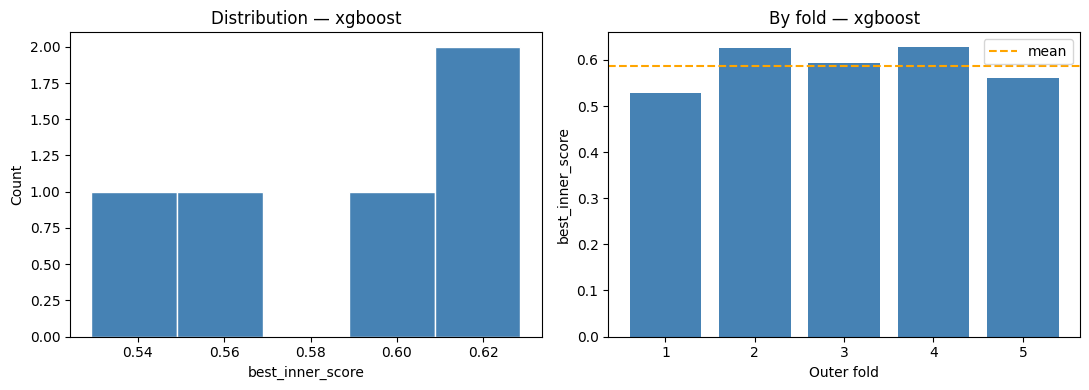

In [20]:
plot_best_inner_score_histogram_and_folds(results_test_df, model_name=best_model_name, model_col="model")

### Calibration curve — Full availability (N=149)

Discrimination metrics (ROC-AUC, F1) show how well the model separates the two classes, but not whether its predicted probabilities are trustworthy on their own. This section checks calibration: for patients where the model predicts a given probability of being polymetastatic, does that probability match the actual observed rate?

Predictions are pooled across all outer folds. The Brier score measures overall probabilistic accuracy, reflecting both calibration and discrimination (lower is better); it is not a pure calibration metric.

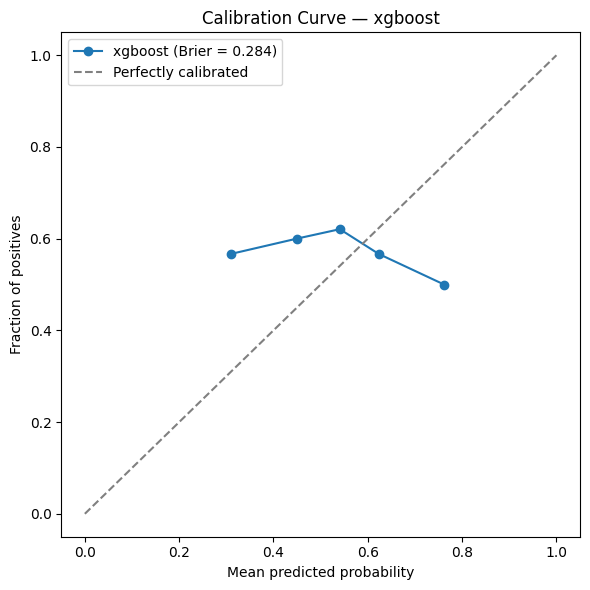

0.284

In [21]:
thesis_display(plot_calibration_curve(selected_oof_df, best_model_name, n_bins=5))


### Calibration curve — Common cohort (N=110)

Selected-family pooled OOF predictions from the shared 110-patient comparison.

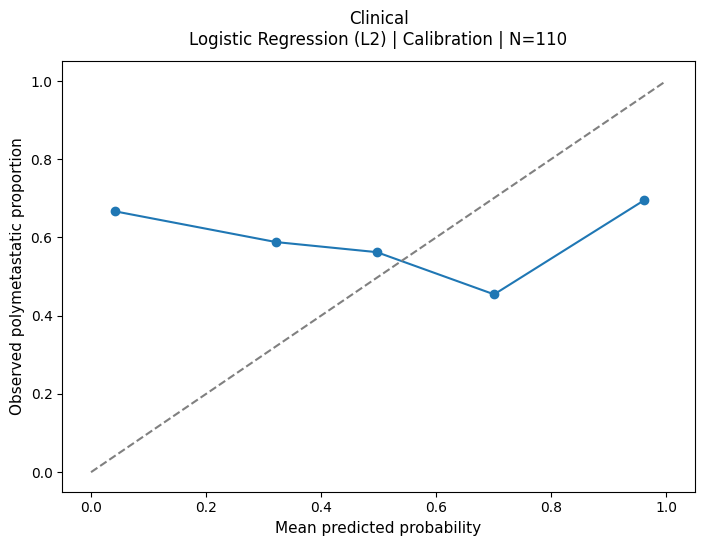

In [32]:
fig = plot_thesis_saved_figure('calibration', 'clinical')
plt.show()


### Interpretation — Full availability (N=149)

The calibration curve indicates poor calibration for the selected XGBoost model. Predicted probabilities are concentrated within a relatively narrow range (approximately 0.30–0.77), while the observed fraction of polymetastatic patients remains mostly between approximately 0.50 and 0.62 across the probability bins.

The curve deviates substantially from the diagonal representing perfect calibration. In the lower predicted-probability bins, the model tends to underestimate the observed proportion of positive cases, whereas in the highest-probability bins it tends to overestimate risk. The relationship between predicted probability and observed outcome frequency is also not consistently monotonic.

The Brier score is 0.284, which further suggests limited probabilistic accuracy. Together with the weak outer-fold discrimination, this means the clinical-only XGBoost model should not be relied on for individual-level probability estimates.

With this small cohort, estimates within individual probability bins may be unstable. The curve indicates limited calibration but cannot precisely characterise individual probability errors.


--- Plotting: Model Selection: Inner-CV Score vs. Test Metrics ---


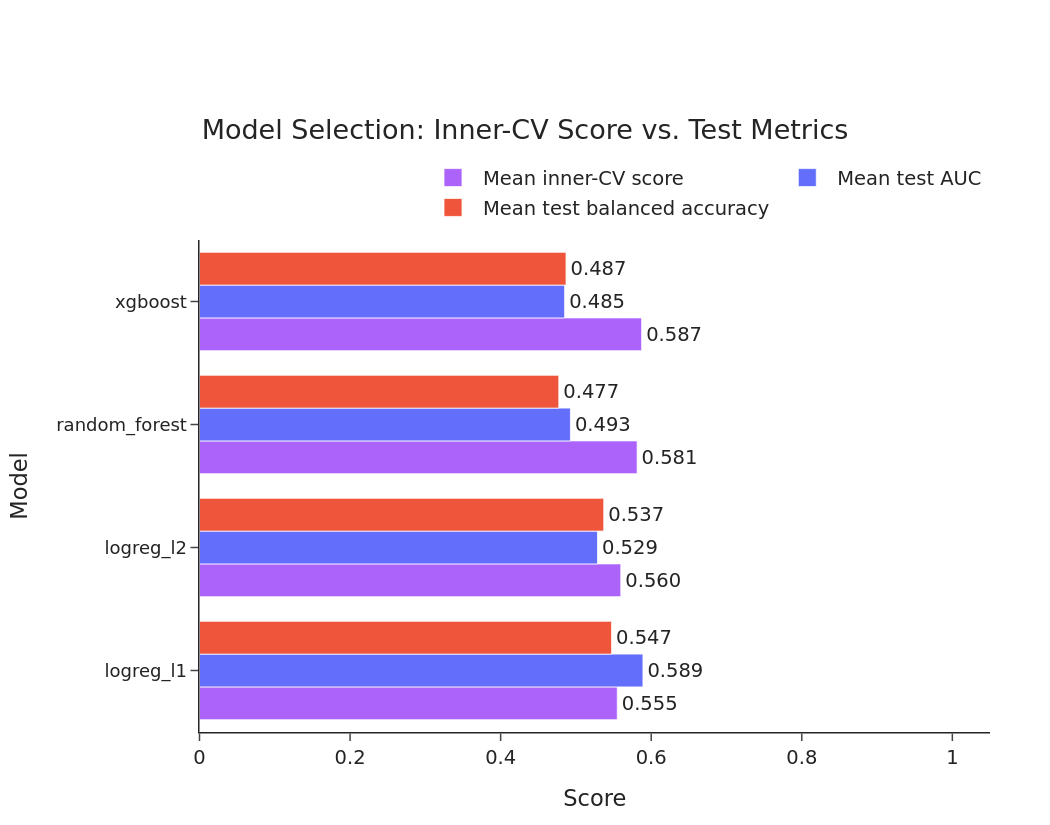

In [22]:
model_selection_plot_df = model_selection_summary.reset_index().rename(
    columns={"index": "model"}
)

plot_combined_ranking(
    model_selection_plot_df,
    sort_by="mean_inner_cv_score",
    metrics=[
        ("mean_inner_cv_score", "#AB63FA", "Mean inner-CV score"),
        ("mean_test_auc_score", "#636EFA", "Mean test AUC"),
        ("mean_test_balanced_accuracy", "#EF553B", "Mean test balanced accuracy"),
    ],
    data_type_col="model",
    title="Model Selection: Inner-CV Score vs. Test Metrics",
    xaxis_title="Score",
    yaxis_title="Model",
    margin=dict(t=160, b=60, l=120, r=40),
    height=550,
    interactive=False
);

## Saved Modelling Results

Model-selection and pooled OOF reports use `_reviewed` filenames. The output categories are listed below.

- fold-level test results;
- fold-level train results;
- fold-level predictions;
- model selection summary based on mean inner-cross-validation score;
- train-versus-test comparison;
- fold-level feature rankings.

In [34]:
thesis_print("Saved files:")
thesis_print(os.path.join(output_dir, "clinical_nested_cv_test_results.csv"))
thesis_print(os.path.join(output_dir, "clinical_nested_cv_train_results.csv"))
thesis_print(os.path.join(output_dir, "clinical_nested_cv_predictions.csv"))
thesis_print(os.path.join(output_dir, "clinical_model_selection_summary_reviewed.csv"))
thesis_print(os.path.join(output_dir, "clinical_train_test_comparison_reviewed.csv"))
thesis_print(os.path.join(output_dir, "clinical_inner_fold_ranking_reviewed.csv"))
thesis_print(os.path.join(output_dir, "clinical_model_fold_wins_reviewed.csv"))
thesis_print(os.path.join(output_dir, "clinical_selected_pooled_oof_metrics_reviewed.csv"))
thesis_print(os.path.join(output_dir, "clinical_nested_cv_feature_rankings.csv"))


Saved files:
/mnt/data3/MCPP-Breast/Machine-Learning-Models-poly_vs_oligo/Clinical-Data/clinical_nested_cv_test_results.csv
/mnt/data3/MCPP-Breast/Machine-Learning-Models-poly_vs_oligo/Clinical-Data/clinical_nested_cv_train_results.csv
/mnt/data3/MCPP-Breast/Machine-Learning-Models-poly_vs_oligo/Clinical-Data/clinical_nested_cv_predictions.csv
/mnt/data3/MCPP-Breast/Machine-Learning-Models-poly_vs_oligo/Clinical-Data/clinical_model_selection_summary.csv
/mnt/data3/MCPP-Breast/Machine-Learning-Models-poly_vs_oligo/Clinical-Data/clinical_train_test_comparison.csv
/mnt/data3/MCPP-Breast/Machine-Learning-Models-poly_vs_oligo/Clinical-Data/clinical_nested_cv_feature_rankings.csv
/mnt/data3/MCPP-Breast/Machine-Learning-Models-poly_vs_oligo/Clinical-Data/xgboost_final_model_top_features.csv
/mnt/data3/MCPP-Breast/Machine-Learning-Models-poly_vs_oligo/Clinical-Data/xgboost_top_feature_group_level_interpretation.csv
/mnt/data3/MCPP-Breast/Machine-Learning-Models-poly_vs_oligo/Clinical-Data/xgbo

> **Supplementary FLAML analysis.** These FLAML (AutoML) results are retained as a supplementary analysis and are not reported in the submitted thesis.

## AutoML comparison (FLAML)

### Rationale and evaluation protocol

FLAML supplements the manual searches with automated model and hyperparameter selection. It was compatible with the project's Python environment, whereas alternatives such as auto-sklearn had version-compatibility limitations. This practical choice does not imply general superiority.

The comparison is meaningful only when both strategies use the same frozen outer splits and selection objective. FLAML optimises macro-F1 (`macro_f1` in FLAML, `f1_macro` in scikit-learn) with five-fold stratified inner CV using only each outer-training partition. The held-out outer-test data are used solely for evaluation. Numeric inputs bypass FLAML's automatic preprocessing and augmentation, avoiding learned preprocessing before its inner CV; candidate learners retain their own fitting behaviour.

`FLAML_TIME_BUDGET_SECONDS` was set to 120 seconds per outer fold and to 120 seconds for the separate full-cohort search. The aligned exports record the selection metric, fold count and budget. Shared splits and objectives support comparison, although the automated and manual searches differ in candidate spaces and computational allocation.

Reference: [Wang et al., *FLAML: A Fast and Lightweight AutoML Library*](https://www.microsoft.com/en-us/research/wp-content/uploads/2021/03/MLSys21FLAML.pdf). Implementation settings follow the [FLAML API documentation](https://microsoft.github.io/FLAML/docs/reference/automl/automl/).

FLAML receives an explicit `StratifiedKFold(n_splits=5, shuffle=True, random_state=42)` for inner validation, as does the manual search. The same ordered outer-training inputs therefore define the same inner-fold membership in the current implementation; FLAML may permute training-row order within a fold. Saved patient-level predictions confirm identical outer-test assignments. Saved summaries document five inner folds but not the inner-validation patient lists, so the exact historical inner-fold membership cannot be verified from them. This is a supplementary comparison in the original analysis context and is not part of common-cohort (N=110) model selection. Separate full-cohort FLAML searches are interpretation-only and have no outer test fold.


In [35]:
if RUN_FLAML:
    flaml_results_test_df, flaml_results_train_df, flaml_predictions_df = (
        run_nested_cv_with_flaml_clinical(
            X=X,
            y=y,
            record_ids=df_clinical["record_id"],
            sample_ids=df_clinical["sample_id"],
            outer_cv=outer_splits,
            time_budget=FLAML_TIME_BUDGET_SECONDS,
            eval_method="cv",
            n_splits=5,
            metric="macro_f1",
            random_state=RANDOM_STATE,
        )
    )

    flaml_results_test_df.to_csv(
        os.path.join(output_dir, "clinical_flaml_aligned_nested_cv_test_results.csv"), index=False
    )
    flaml_results_train_df.to_csv(
        os.path.join(output_dir, "clinical_flaml_aligned_nested_cv_train_results.csv"), index=False
    )
    flaml_predictions_df.to_csv(
        os.path.join(output_dir, "clinical_flaml_aligned_nested_cv_predictions.csv"), index=False
    )

    thesis_display(flaml_results_test_df[["outer_fold", "auc_score", "balanced_accuracy", "best_inner_score", "best_params"]])
else:
    flaml_results_test_df = p110_pd.read_csv(p110_root.parent / p110_folder / 'clinical_flaml_aligned_nested_cv_test_results.csv')
    flaml_results_train_df = p110_pd.read_csv(p110_root.parent / p110_folder / 'clinical_flaml_aligned_nested_cv_train_results.csv')
    flaml_predictions_df = p110_pd.read_csv(p110_root.parent / p110_folder / 'clinical_flaml_aligned_nested_cv_predictions.csv')
    thesis_display(flaml_results_test_df[['outer_fold', 'auc_score', 'balanced_accuracy', 'best_inner_score', 'best_params']])



=== FLAML | Outer fold 1/5 ===



--- Calculating Model Performance Metrics ---
Accuracy: 0.633
F1_score: 0.686
Sensitivity: 0.706
Specificity: 0.538
Auc_score: 0.640
Precision: 0.667

Metrics calculated successfully.

--- Calculating Model Performance Metrics ---
Accuracy: 0.656
F1_score: 0.728
Sensitivity: 0.809
Specificity: 0.451
Auc_score: 0.683
Precision: 0.663

Metrics calculated successfully.

=== FLAML | Outer fold 2/5 ===

--- Calculating Model Performance Metrics ---
Accuracy: 0.400
F1_score: 0.500
Sensitivity: 0.529
Specificity: 0.231
Auc_score: 0.348
Precision: 0.474

Metrics calculated successfully.

--- Calculating Model Performance Metrics ---
Accuracy: 0.891
F1_score: 0.908
Sensitivity: 0.941
Specificity: 0.824
Auc_score: 0.937
Precision: 0.877

Metrics calculated successfully.

=== FLAML | Outer fold 3/5 ===

--- Calculating Model Performance Metrics ---
Accuracy: 0.467
F1_score: 0.529
Sensitivity: 0.529
Specificity: 0.385
Auc_score: 0.493
Precision: 0.529

Metrics calculated successfully.

--- Calcul

,outer_fold,auc_score,balanced_accuracy,best_inner_score,best_params
0,1,0.640,0.622,0.625,"{""best_estimator"": ""xgboost"", ""best_config"": {..."
1,2,0.348,0.380,0.669,"{""best_estimator"": ""xgb_limitdepth"", ""best_con..."
2,3,0.493,0.457,0.662,"{""best_estimator"": ""rf"", ""best_config"": {""n_es..."
3,4,0.452,0.466,0.693,"{""best_estimator"": ""extra_tree"", ""best_config""..."
4,5,0.554,0.507,0.612,"{""best_estimator"": ""extra_tree"", ""best_config""..."


### Comparison with Manually Specified Models

,metric,pooled_oof_value
0,ROC-AUC,0.486
1,Balanced accuracy,0.488
2,Macro-F1,0.486
3,Precision (polymetastatic = 1),0.560
4,Sensitivity (polymetastatic = 1),0.600
5,Specificity (oligometastatic = 0),0.375
6,Average precision (PR),0.593
7,Brier score,0.283


--- Plotting ROC Curve ---


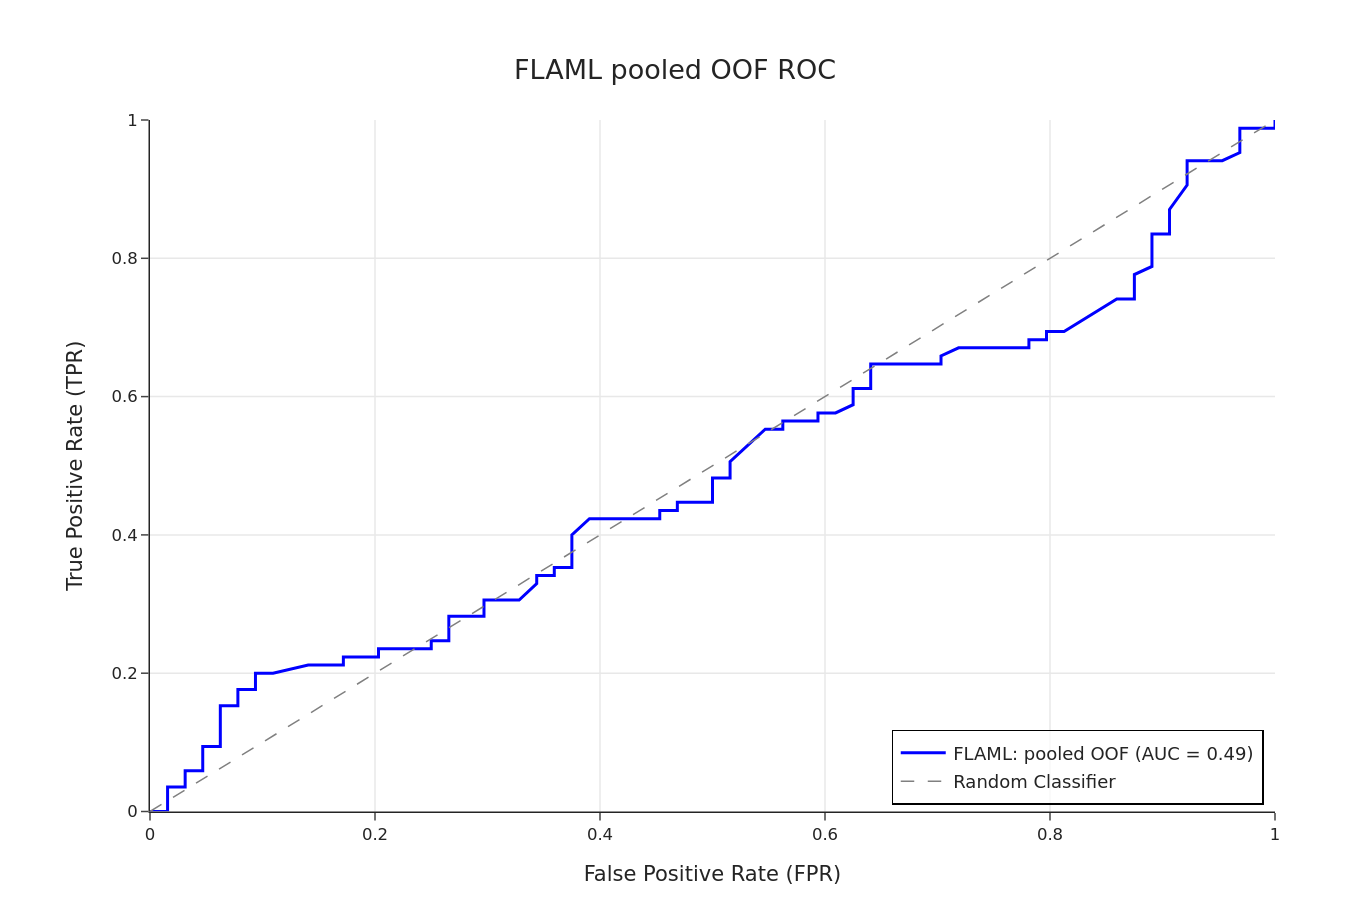

--- Plotting Precision–Recall Curve ---


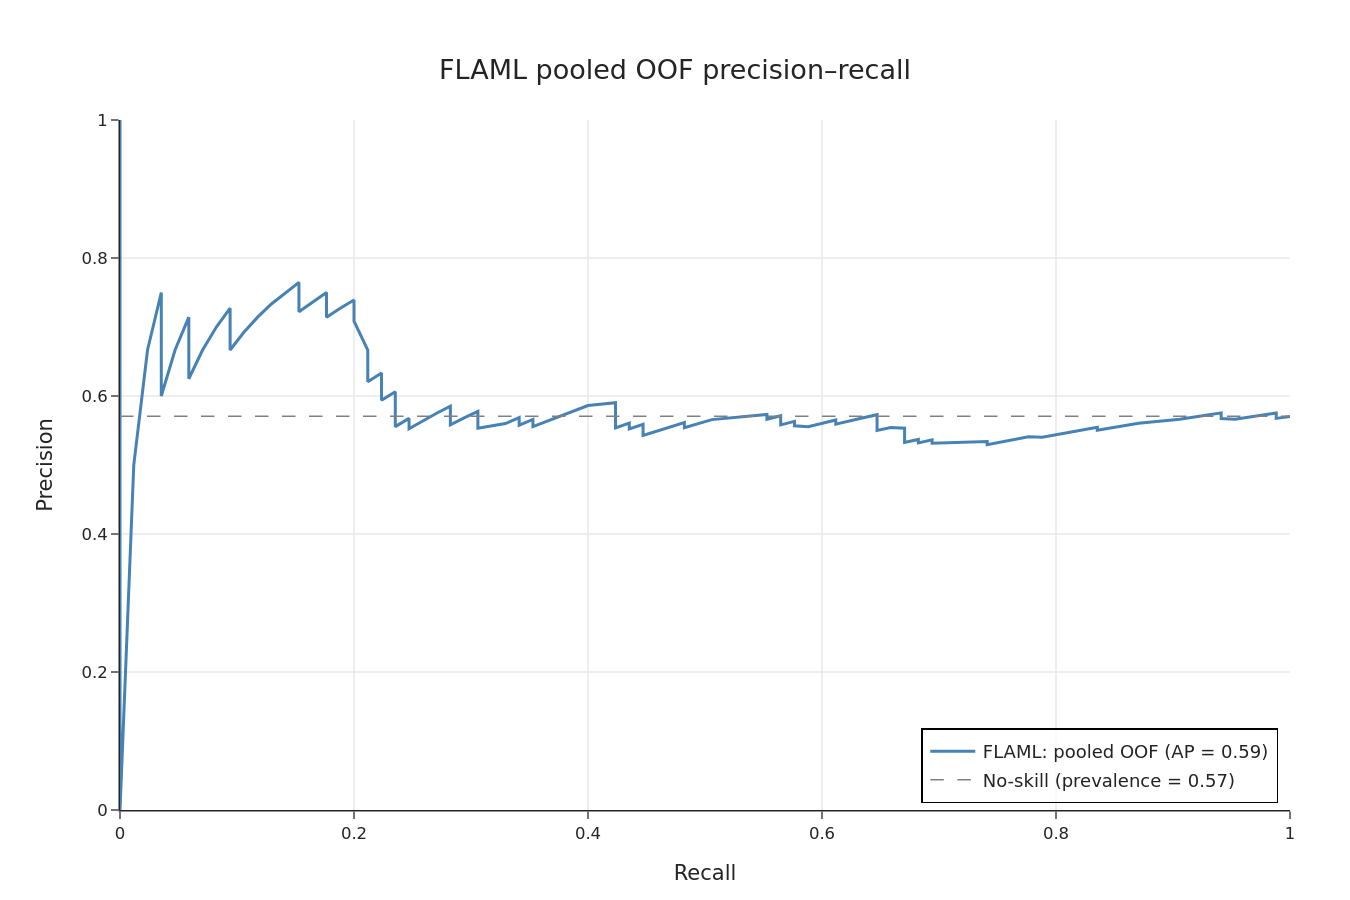

best_inner_score           auc_score            \
                          mean       std      mean       std   
model                                                          
flaml_automl          0.652  0.033  0.498  0.109   
xgboost               0.587  0.043  0.485  0.162   
random_forest         0.581  0.032  0.493  0.094   
logreg_l2             0.560  0.028  0.529  0.106   
logreg_l1             0.555  0.038  0.589  0.059   

              balanced_accuracy            macro_f1           precision  \
                           mean       std      mean       std      mean   
model                                                                     
flaml_automl           0.487  0.089  0.482  0.090  0.559   
xgboost                0.487  0.131  0.478  0.144  0.572   
random_forest          0.477  0.058  0.459  0.075  0.550   
logreg_l2              0.537  0.085  0.528  0.090  0.599   
logreg_l1              0.547  0.022  0.536  0.027  0.611   

                        sensitivity           specificity            \
                    std        mean       std        mean       std   
model                                                                 
flaml_automl   0.073    0.600  0.128    0.373  0.133   
xgboost        0.101    0.565  0.032    0.409  0.247   
random_forest  0.047    0.565  0.184    0.390  0.209   
logreg_l2      0.064    0.576  0.192    0.497  0.152   
logreg_l1      0.025    0.659  0.174    0.436  0.173   

              average_precision           brier_score            
                           mean       std        mean       std  
model                                                            
flaml_automl           0.628  0.044    0.283  0.047  
xgboost                0.622  0.114    0.284  0.052  
random_forest          0.616  0.087    0.270  0.026  
logreg_l2              0.621  0.080    0.255  0.020  
logreg_l1              0.656  0.048    0.249  0.009

In [36]:
if RUN_FLAML:
    flaml_oof_df = validate_clinical_oof(flaml_predictions_df, "flaml_automl", df_clinical, outer_splits)
    flaml_pooled = clinical_binary_metrics(flaml_oof_df.y_true, flaml_oof_df.y_pred, flaml_oof_df.y_proba)
    thesis_display(pd.DataFrame([{"metric": label, "pooled_oof_value": flaml_pooled[key]}
                          for key, label in pooled_metric_labels.items()]))
    flaml_curves = [{"y_true": flaml_oof_df.y_true.to_numpy(), "y_prob": flaml_oof_df.y_proba.to_numpy(),
                     "label": "FLAML: pooled OOF", "is_main_curve": True}]
    plot_roc_curves(flaml_curves, title="FLAML pooled OOF ROC", interactive=False)
    plot_precision_recall_curves(flaml_curves, title="FLAML pooled OOF precision–recall", interactive=False)
    comparison_df = pd.concat([report_test_df, flaml_results_test_df], ignore_index=True)
    flaml_evaluation_summary = comparison_df.groupby("model")[[
        "best_inner_score", "auc_score", "balanced_accuracy", "macro_f1",
        "precision", "sensitivity", "specificity", "average_precision", "brier_score"
    ]].agg(["mean", "std"]).sort_values(("best_inner_score", "mean"), ascending=False)
    thesis_display(flaml_evaluation_summary)
    flaml_evaluation_summary.to_csv(Path(output_dir) / "clinical_flaml_aligned_comparison.csv")
else:
    thesis_print("Aligned FLAML comparison awaits an authorised run with the agreed budget.")

**Full availability (N=149).** Under the aligned protocol, FLAML achieved mean inner-CV macro-F1 of 0.652, compared with 0.587 for manual XGBoost. Mean outer-fold ROC-AUC was 0.498 for FLAML and 0.485 for XGBoost; their pooled OOF ROC-AUC values were 0.486 and 0.474, respectively.

The higher FLAML inner score did not translate into convincing held-out discrimination. These descriptive results do not establish superiority, particularly given the small cohort, fold variability and different search spaces and budgets. The manual interpretation family remains XGBoost under the predefined mean inner-CV criterion; outer-test metrics do not determine the selected model.

### Full-cohort FLAML model for exploratory inspection

The full-cohort FLAML search used macro-F1, five-fold stratified CV and a 120-second budget, matching the objective, inner-fold count and per-search budget of nested FLAML. It selected Extra Trees and refitted the model on the complete cohort for exploratory inspection after performance evaluation.

Neither its CV score nor its training score is an unbiased predictive-performance estimate. This full-cohort model does not replace the fold-specific models used to obtain FLAML's held-out predictions.

In [37]:
final_automl = None
if RUN_FULL_COHORT_FLAML:
    if not RUN_FLAML:
        raise RuntimeError("Complete aligned nested FLAML and freeze its estimates before full-cohort inspection.")
    final_automl = AutoML()
    final_automl.fit(X_train=X, y_train=y,
        **clinical_flaml_settings(FLAML_TIME_BUDGET_SECONDS, SELECTION_SCORING, RANDOM_STATE))
    thesis_print("Exploratory full-cohort estimator:", final_automl.best_estimator)
    thesis_print("Exploratory configuration:", final_automl.best_config)
else:
    thesis_print("Full-cohort FLAML skipped.")

Exploratory full-cohort estimator: extra_tree
Exploratory configuration: {'n_estimators': 10, 'max_features': np.float64(0.29354930903460813), 'max_leaves': 6, 'criterion': np.str_('gini')}


**Full availability (N=149).** The full-cohort search selected Extra Trees (`extra_tree`) with `n_estimators=10`, `max_features=0.29354930903460813`, `max_leaves=6` and `criterion='gini'`. This configuration describes the exploratory full-cohort model; its selection does not establish Extra Trees as an independently validated best family.

## Conclusion and limitations

### Full availability (N=149)

XGBoost was selected by the predefined mean inner-CV macro-F1 criterion (0.5873), with three of five fold wins. Its mean outer-fold ROC-AUC was 0.485 and pooled OOF ROC-AUC was 0.474, so convincing clinical-only discrimination was not demonstrated. Outer-test metrics describe performance and never determine model selection.

The modelling CSV was filtered and encoded upstream using the full cohort, including missingness and feature-frequency/correlation filtering. Those upstream choices were not nested in this notebook's CV. In addition, the existing XGBoost grid includes a class-ratio value computed from the full cohort labels, rather than only an outer-training partition. These inherited limitations constrain claims of fully unbiased pipeline evaluation. Global model-family selection across outer folds also lacks independent validation, as explained in the pooled evaluation section.

### Common cohort (N=110)

L2 logistic regression was selected by the highest mean inner-CV macro-F1 (0.557). Pooled OOF ROC-AUC was 0.485, balanced accuracy 0.506, macro-F1 0.497 and Brier score 0.368. This is the common-cohort result for cross-modality comparison on the same 110 patients and frozen outer folds. Performance remains exploratory and does not establish clinical utility. Differences between contexts involve preprocessing and search spaces as well as cohort membership; they cannot be attributed solely to sample size.

The common-cohort (N=110) clinical model is interpreted separately using coefficients from the dedicated interpretation-only L2 logistic-regression fit.